# Predicción de la desviación temporal del transporte público de Cusco
## Entregable 2: Implementación y Evaluación Experimental — Notebook

**Curso:** 1INF02 – Aprendizaje de Máquina · **Horario:** H-1081

**Autores:** Italo Marcelo Carrion Segura · Mauricio Lucio Arenales Aquino · Alvaro Erlin Pesantes Advincula · Italo Mijail Ramos Diaz

**Docentes:** Dr. Edwin Alvarez Mamani · Dr. César Armando Beltrán Castañón

Este notebook acompaña al informe y contiene solo lo necesario para sustentar sus secciones. Su jerarquía sigue la del informe:

| Sección del notebook | Sección del informe |
|---|---|
| 1.- Configuración del entorno | Metodología Experimental → Entorno Computacional |
| 2.- Carga e inspección de los datos | Dataset y Variables Relevantes |
| 3.- **Preprocesamiento de datos** (3.1 limpieza: nulos, duplicados, atípicos, Monitoring · 3.2 transformación · 3.3 partición · 3.4 escalamiento) | EDA → Valores Faltantes, Duplicados y Atípicos · Preprocesamiento → Limpieza, Transformación, Escalamiento · Estrategia de Validación y Partición |
| 4.- Análisis exploratorio (EDA) | EDA → Estadísticos Descriptivos · Distribuciones y Relaciones |
| 5.- Modelado y evaluación (5.1–5.8 referencias, modelos, curvas, comparación y errores en validación · 5.9 selección de características · 5.10 optimización de hiperparámetros · 5.11 selección del modelo final) | Algoritmos → Hiperparámetros · Metodología (métricas, protocolo, Pasos 1–4) · Experimentos y Resultados (por modelo, ajuste, comparación) |
| 6.- Evaluación final en *test* (6.1 métricas con IC · 6.2 análisis de errores · 6.3 interpretabilidad: permutación y SHAP · 6.4 clustering de vueltas) | Protocolo, Pasos 5 y 6 · Experimentos y Resultados → Análisis de Errores |
| 7.- Resumen de resultados | Comparación de Modelos · Conclusiones |

**Convenciones.** `k` es el punto de control (1…18). La variable objetivo es `difference_time` (minutos; negativo = el bus llegó antes de lo programado, positivo = llegó tarde). Las predictoras se construyen **solo con información previa al punto `k`** para evitar fuga de información.

## 1.- Configuración del entorno

In [1]:
import os, time, random, platform, warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn

warnings.filterwarnings("ignore")

# ---------------- Parámetros del experimento ----------------
SEED = 42
N_POINTS = 18                      # puntos de control por vuelta
OUTLIER_MIN = 30                   # |difference_time| > 30 min => registro erróneo (sección 3.1.4)
MISSING_END_SENTINEL = "00:00:00"  # valor que usa el sistema cuando no registró la hora real (sección 3.1.2)

# Partición cronológica por semanas completas (sección 3.3)
TRAIN_END = "2025-01-19"           # train: 6 al 19 de enero
VAL_END = "2025-01-26"             # validación: 20 al 26 de enero | test: 27 de enero al 1 de febrero

# Ajuste de hiperparámetros (sección 5.3)
RUN_TUNING = True                  # búsqueda aleatoria; False = hiperparámetros por defecto
N_ITER = 8                         # configuraciones evaluadas por modelo (aumentar para la versión final)
CV_SPLITS, MIN_TRAIN_DAYS = 4, 6   # validación cruzada temporal: ventana expansiva por días

# Selección final y optimización (secciones 5.9 a 5.11)
BORUTA_ITER = 40                   # iteraciones del algoritmo de sombras (Boruta)
N_ITER_FINAL, CV2_SPLITS = 15, 5   # búsqueda ampliada de los finalistas, con CV temporal sobre train + validación
MARGIN_MAE = 0.02                  # diferencia de MAE (min) por debajo de la cual dos configuraciones se consideran equivalentes

FINAL_TEST = True                  # evaluación en test (sección 6): ejecutar UNA sola vez, con todas las decisiones ya tomadas

# Fuentes de datos: resolución automática con prioridad a archivos locales y fallback remoto
def resolve_data_source(env_var, local_candidates, default_url):
    val = os.environ.get(env_var)
    if val and os.path.exists(val): return val
    for p in local_candidates:
        if os.path.exists(p): return p
    return default_url

TIMES_SRC = resolve_data_source("TIMES_CSV", ["TA/Dataset/Times.csv", "Dataset/Times.csv", "Times.csv"],
                                "https://drive.google.com/uc?export=download&id=1zsnH0IuXNU_Jt6YcBvct34_s-SjCOL_w")
MONITORING_SRC = resolve_data_source("MONITORING_CSV", ["TA/Dataset/Monitoring.csv", "Dataset/Monitoring.csv", "Monitoring.csv"],
                                     "https://drive.usercontent.google.com/download?id=1RkWfxHCiT-A3A-GK9LFC8CXpNW_EN90T&export=download&confirm=t")

# Librerías opcionales de boosting (si no están, el notebook las omite): pip install lightgbm xgboost
try:
    import lightgbm as lgb
except Exception:
    lgb = None
try:
    import xgboost as xgb
except Exception:
    xgb = None

# Reproducibilidad y estilo visual
random.seed(SEED); np.random.seed(SEED)
FIG_DIR = os.environ.get("NB_FIG_DIR", "figures"); os.makedirs(FIG_DIR, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 140)

def save_fig(name):
    plt.savefig(os.path.join(FIG_DIR, f"{name}.png"), bbox_inches="tight")

# ---------------- Entorno computacional (para el informe) ----------------
print("Python       :", platform.python_version())
for lib in (np, pd, scipy, sklearn, matplotlib, sns):
    print(f"{lib.__name__:<13}:", lib.__version__)
print("lightgbm     :", lgb.__version__ if lgb else "no disponible")
print("xgboost      :", xgb.__version__ if xgb else "no disponible")
print("Semilla      :", SEED)

Python       : 3.13.18
numpy        : 2.4.6
pandas       : 2.2.3
scipy        : 1.16.3
sklearn      : 1.6.1
matplotlib   : 3.10.0
seaborn      : 0.13.2
lightgbm     : 4.6.0
xgboost      : 3.4.1
Semilla      : 42


## 2.- Carga e inspección de los datos

### 2.1.- `Times.csv` y Auditoría Semántica de la Variable Objetivo
Cada fila es **una vuelta de un vehículo**; `start_time` (hora programada), `end_time` (hora real) y `difference_time` (desviación en minutos) son **listas de 18 valores** `{v1,...,v18}`, una por punto de control.

> **Auditoría Semántica y Corrección respecto al README original:**
> El `README.txt` original del dataset describe `start_time` como *inicio del tramo*, `end_time` como *fin del tramo* y `difference_time` como *tiempo total del tramo*. 
> Sin embargo, la auditoría empírica y matemática demuestra que dicha descripción del README es errónea:
> 1. El 100.0% de los registros de `start_time` terminan en `:00` (minuto en punto) y crecen a lo largo de los 18 puntos; corresponden a los **horarios programados (itinerario)** en cada punto $k$.
> 2. `end_time` contiene segundos de telemetría GPS (`HH:MM:SS`), que corresponden a la **hora real de paso** por el punto $k$.
> 3. `difference_time` toma valores tanto positivos (retrasos) como negativos (adelantos, 26.2% de los datos). Un tiempo físico de tramo jamás podría ser negativo.
> 4. `difference_time` coincide en el 99.84% de los casos válidos con la **parte entera truncada hacia cero** de $(	ext{end\_time} - 	ext{start\_time})$ en minutos.
> 5. **Efecto de cuantización:** Dado el truncamiento entero, un valor `difference_time = 0` no denota puntualidad exacta al segundo, sino una llegada en el intervalo $[-59\,\text{s}, +59\,\text{s}]$ respecto al horario programado.

In [2]:
times_raw = pd.read_csv(TIMES_SRC, dtype={"vehicle_id_id": str})
print("Forma de Times.csv:", times_raw.shape)
times_raw.head(3)

Forma de Times.csv: (4707, 8)


,id,lap,date,time,start_time,end_time,difference_time,vehicle_id_id
0,24945,1,2025-01-22,05:45:00,"{05:45:00,05:47:00,05:56:00,06:10:00,06:21:00,...","{05:44:03,05:44:54,05:53:52,06:09:29,06:16:50,...","{0,-2,-2,0,-4,-4,-4,-3,-1,0,1,1,1,3,2,-1,0,-1}",17
1,6772,1,2025-01-06,06:14:00,"{06:14:00,06:16:00,06:27:00,06:44:00,06:57:00,...","{06:12:55,06:13:46,06:24:00,06:42:25,06:54:09,...","{-1,-2,-3,-1,-2,-5,-5,-5,-5,-3,-1,-1,-2,0,-2,-...",09
2,24976,1,2025-01-22,06:00:00,"{06:00:00,06:02:00,06:11:00,06:25:00,06:36:00,...","{05:58:15,05:59:45,06:09:19,06:25:34,06:34:38,...","{-1,-2,-1,0,-1,-1,-2,0,1,0,0,0,-2,-1,-2,0,0,0}",20


### 2.2.- `Monitoring.csv`

In [3]:
mon_raw = pd.read_csv(MONITORING_SRC, dtype={"vehicle_id_id": str})
print("Forma de Monitoring.csv:", mon_raw.shape)
mon_raw.head(3)

Forma de Monitoring.csv: (1630431, 9)


,id,date,time,lap,latitude,longitude,speed,bearing,vehicle_id_id
0,602216,2025-01-01,06:33:38,0,-13.551461,-71.988751,24,114,05
1,606285,2025-01-01,08:02:37,0,-13.551343,-71.987746,21,53,20
2,614423,2025-01-01,10:06:37,0,-13.526030,-71.983348,18,27,17


### 2.3.- Inspección inicial

In [4]:
resumen = pd.DataFrame({
    "Times.csv": {
        "filas (vueltas)": len(times_raw), "columnas": times_raw.shape[1],
        "fecha mínima": times_raw["date"].min(), "fecha máxima": times_raw["date"].max(),
        "días distintos": times_raw["date"].nunique(), "vehículos distintos": times_raw["vehicle_id_id"].nunique(),
        "vueltas (lap) distintas": times_raw["lap"].nunique(),
    }
})
display(resumen)
print("Longitud de las listas por fila:",
      {c: times_raw[c].str.strip("{}").str.split(",").str.len().value_counts().to_dict() for c in ["start_time", "end_time", "difference_time"]})

,Times.csv
filas (vueltas),4707
columnas,8
fecha mínima,2025-01-06
fecha máxima,2025-02-01
días distintos,27
vehículos distintos,45
vueltas (lap) distintas,8


Longitud de las listas por fila: {'start_time': {18: 4707}, 'end_time': {18: 4707}, 'difference_time': {18: 4707}}


## 3.- Preprocesamiento de datos

Bloque completo de preparación de los datos, en el orden en que se ejecuta: **limpieza** (estructuración, nulos, duplicados e inconsistencias, atípicos y limpieza de `Monitoring`), **transformación de variables**, **partición cronológica** y **escalamiento/codificación**.

### 3.1.- Limpieza de datos

#### 3.1.1.- Estructuración: expansión de listas y estandarización de tipos

Cada vuelta se convierte en **18 observaciones** (una por punto de control `k`). Se verifica que las tres listas tengan igual longitud, se expanden con `explode` y se convierten los tipos: `date` → `datetime64`; `start_time`/`end_time` → marcas de tiempo completas (`sched_ts` programada, `real_ts_raw` real); `difference_time` → número (el sistema usa `"-"` cuando no hay dato, tratado en 3.1.2); `vehicle_id` se mantiene como **texto** (identificador, no cantidad).

In [5]:
LIST_COLS = ["start_time", "end_time", "difference_time"]
lists = {c: times_raw[c].str.strip().str.strip("{}").str.split(",") for c in LIST_COLS}

obs = (times_raw.rename(columns={"id": "lap_id"}).drop(columns=LIST_COLS)
                .assign(**lists).explode(LIST_COLS).reset_index(drop=True))
obs["k"] = obs.groupby("lap_id").cumcount() + 1
print(f"{len(times_raw):,} vueltas  ->  {len(obs):,} observaciones  ({N_POINTS} por vuelta)")

# Tipos
obs["date"] = pd.to_datetime(obs["date"])
obs["sched_ts"] = obs["date"] + pd.to_timedelta(obs["start_time"])       # hora programada en el punto k
obs["real_ts_raw"] = obs["date"] + pd.to_timedelta(obs["end_time"])      # hora real (aún con el valor centinela 00:00:00)
is_dash = obs["difference_time"].eq("-")
obs["diff_raw"] = pd.to_numeric(obs["difference_time"].where(~is_dash), errors="coerce")
obs["vehicle_id"] = obs["vehicle_id_id"].astype(str)
obs = obs.drop(columns=["vehicle_id_id"])

# Variables temporales de apoyo (hora programada, franja y día de la semana)
obs["hour_sched"] = obs["sched_ts"].dt.hour + obs["sched_ts"].dt.minute / 60
obs["franja"] = pd.cut(obs["hour_sched"], bins=[-1, 6, 9, 14, 18, 24], right=False,
                       labels=["Madrugada (<6h)", "Mañana (6-9h)", "Mediodía (9-14h)", "Tarde (14-18h)", "Noche (>=18h)"])
obs["dow"] = obs["date"].dt.dayofweek        # 0 = lunes ... 6 = domingo
obs.head(4)[["lap_id", "k", "date", "sched_ts", "real_ts_raw", "diff_raw", "vehicle_id"]]

4,707 vueltas  ->  84,726 observaciones  (18 por vuelta)


,lap_id,k,date,sched_ts,real_ts_raw,diff_raw,vehicle_id
0,24945,1,2025-01-22,2025-01-22 05:45:00,2025-01-22 05:44:03,0.0,17
1,24945,2,2025-01-22,2025-01-22 05:47:00,2025-01-22 05:44:54,-2.0,17
2,24945,3,2025-01-22,2025-01-22 05:56:00,2025-01-22 05:53:52,-2.0,17
3,24945,4,2025-01-22,2025-01-22 06:10:00,2025-01-22 06:09:29,0.0,17


#### 3.1.2.- Valores nulos

En `Times.csv` no hay celdas vacías, pero sí **nulos codificados**: `difference_time = "-"`. La hipótesis es que corresponden a puntos de control **sin hora real registrada**, para los que el sistema escribe `end_time = 00:00:00`. Se contrasta y se analiza su patrón.

Celdas vacías en Times.csv: 0


end_time == 00:00:00,False,True,All
difference_time == '-',,,
False,76980,0,76980
True,0,7746,7746
All,76980,7746,84726


Observaciones con difference_time nulo: 7,746 de 84,726 (9.14%)


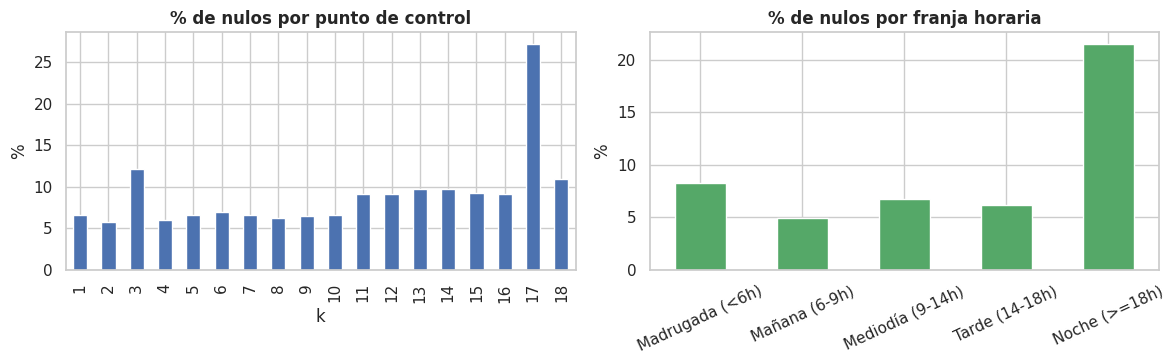

Vueltas completas: 65.2% | con algún nulo: 34.8% | 100% nulas: 29


In [6]:
obs["diff_missing"] = obs["diff_raw"].isna()
obs["end_sentinel"] = obs["end_time"].eq(MISSING_END_SENTINEL)
print("Celdas vacías en Times.csv:", int(times_raw.isna().sum().sum()))
display(pd.crosstab(obs["diff_missing"].rename("difference_time == '-'"), obs["end_sentinel"].rename("end_time == 00:00:00"), margins=True))
print(f"Observaciones con difference_time nulo: {obs['diff_missing'].sum():,} de {len(obs):,} ({obs['diff_missing'].mean():.2%})")

# Ambos patrones coinciden: end_time = 00:00:00 no es medianoche, es "sin registro" -> NaT
obs["real_ts"] = obs["real_ts_raw"].where(~obs["end_sentinel"])
obs = obs.drop(columns=["real_ts_raw"])
assert obs["real_ts"].isna().equals(obs["diff_missing"])

# Patrón de los nulos
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
obs.groupby("k")["diff_missing"].mean().mul(100).plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set(title="% de nulos por punto de control", xlabel="k", ylabel="%")
obs.groupby("franja", observed=True)["diff_missing"].mean().mul(100).plot.bar(ax=axes[1], color="#55A868", rot=25)
axes[1].set(title="% de nulos por franja horaria", xlabel="", ylabel="%")
plt.tight_layout(); save_fig("nulos_patron"); plt.show()

lap_missing = obs.groupby("lap_id")["diff_missing"].sum()
print(f"Vueltas completas: {(lap_missing == 0).mean():.1%} | con algún nulo: {(lap_missing > 0).mean():.1%} | 100% nulas: {(lap_missing == N_POINTS).sum()}")

**Decisión.**

| Elemento | Tratamiento | Justificación |
|---|---|---|
| **Variable objetivo** (`difference_time`) | **No se imputa**; las observaciones con objetivo nulo se excluyen del entrenamiento y la evaluación | Imputar el objetivo inventaría la respuesta y sesgaría las métricas |
| **Predictoras derivadas** (rezagos, velocidad de Monitoring, etc.) | Se dejan como `NaN` y se tratan **dentro del pipeline**: imputación por mediana + indicador de faltante (lineales/MLP) o manejo nativo de `NaN` (boosting) | La imputación se ajusta solo con *train* (sin fuga) |
| **Vueltas 100 % nulas** | Se conservan en la tabla; se excluyen automáticamente al filtrar por objetivo no nulo | No aportan objetivo, pero tampoco estorban |

#### 3.1.3.- Duplicados e inconsistencias

In [7]:
# (a) Duplicados
chk = {
    "id duplicado (nivel vuelta)": times_raw["id"].duplicated().sum(),
    "fila duplicada (todas las columnas salvo id)": times_raw.drop(columns="id").duplicated().sum(),
    "misma (vehículo, fecha, lap)": times_raw.duplicated(["vehicle_id_id", "date", "lap"]).sum(),
    "misma (vehículo, fecha, hora de inicio)": times_raw.duplicated(["vehicle_id_id", "date", "time"]).sum(),
    "observación duplicada (lap_id, k)": obs.duplicated(["lap_id", "k"]).sum(),
}
display(pd.Series(chk, name="n duplicados").to_frame())

# (b) Consistencia interna
valid = obs.dropna(subset=["real_ts"]).copy()
calc_min = (valid["real_ts"] - valid["sched_ts"]).dt.total_seconds() / 60
print("difference_time == trunc(real - programada):", (np.trunc(calc_min) == valid["diff_raw"]).mean().round(4),
      "| con round():", (np.round(calc_min) == valid["diff_raw"]).mean().round(4))
first = obs[obs["k"] == 1].set_index("lap_id")
print("time == start_time[0]:", (times_raw.set_index("id")["time"].reindex(first.index) == first["start_time"]).mean().round(4))

# (c) Horario programado desordenado (debería ser no decreciente a lo largo de la vuelta)
obs = obs.sort_values(["lap_id", "k"]).reset_index(drop=True)
obs["sched_step_min"] = obs.groupby("lap_id")["sched_ts"].diff().dt.total_seconds() / 60
lap_disorder = (obs["sched_step_min"] < 0).groupby(obs["lap_id"]).any()
obs["sched_disorder"] = obs["lap_id"].map(lap_disorder)
print(f"Vueltas con horario programado desordenado: {lap_disorder.sum()} ({lap_disorder.mean():.2%}); "
      f"todas con nulos: {bool((lap_missing[lap_disorder[lap_disorder].index] > 0).all())}")

# (d) Vueltas fragmentadas: mismo vehículo + fecha + hora de inicio, pero distinto id/lap
frag = times_raw[times_raw.duplicated(["vehicle_id_id", "date", "time"], keep=False)].copy()
frag["trip"] = frag.groupby(["vehicle_id_id", "date", "time"]).ngroup()
disjuntos = np.mean([(np.array([[x != "-" for x in t.strip("{}").split(",")] for t in g]).sum(axis=0) <= 1).all()
                     for _, g in frag.groupby("trip")["difference_time"]])
print(f"Viajes fragmentados: {frag['trip'].nunique()} grupos ({len(frag)} vueltas); "
      f"con puntos válidos complementarios (no solapados): {disjuntos:.1%}")
obs["dup_trip"] = obs["lap_id"].isin(frag["id"])

,n duplicados
id duplicado (nivel vuelta),0
fila duplicada (todas las columnas salvo id),0
"misma (vehículo, fecha, lap)",0
"misma (vehículo, fecha, hora de inicio)",120
"observación duplicada (lap_id, k)",0


difference_time == trunc(real - programada): 1.0 | con round(): 0.5428
time == start_time[0]: 1.0
Vueltas con horario programado desordenado: 148 (3.14%); todas con nulos: True
Viajes fragmentados: 118 grupos (238 vueltas); con puntos válidos complementarios (no solapados): 85.6%


**Hallazgos y decisión.**
- No hay duplicados exactos (ni por `id`, ni por fila, ni por `(lap_id, k)`).
- `difference_time` es la parte **entera truncada** de (hora real − programada); el objetivo es entero, con resolución de +-1 min.
- **Horario desordenado:** un grupo pequeño de vueltas trae horarios programados mezclados y todas tienen nulos en los puntos afectados. No se eliminan: las variables derivadas del horario (`sched_gap_min`, `offset_min`) se ponen en `NaN` en esas vueltas (3.2) y queda la bandera `sched_disorder`.
- **Vueltas fragmentadas:** no son copias, sino un mismo viaje repartido en dos registros (cada uno con una parte de los puntos). No se descartan ni se fusionan (la fusión exigiría reconstruir el horario correcto); como pertenecen al mismo día, no cruzan particiones. Queda la bandera `dup_trip` para análisis de sensibilidad y la fusión como trabajo futuro.

#### 3.1.4.- Valores atípicos

,0.000,0.001,0.010,0.050,0.250,0.500,0.750,0.950,0.990,0.999,1.000
difference_time (min),-1052.0,-945.0,-16.0,-5.0,-1.0,0.0,2.0,10.0,19.0,31.0,631.0


Regla IQR (1.5·IQR): fuera de [-5.5, 6.5] -> 13.8% de las observaciones
Regla de dominio |d| > 30 min -> 238 obs. (0.31%)
|d| > 120 min: 138 obs. en 47 vueltas | tras corregir +-24 h, dentro de +-30 min: 0.0%


,obs. eliminadas,% eliminado,media,desv. estándar,MAE vs. cero
umbral |d| <=,,,,,
10,5538,7.194,0.628,2.938,1.898
15,2233,2.901,0.685,3.911,2.372
20,861,1.118,0.751,4.527,2.646
30,238,0.309,0.861,4.975,2.817
45,168,0.218,0.886,5.088,2.847
60,156,0.203,0.884,5.129,2.855
120,138,0.179,0.880,5.335,2.876


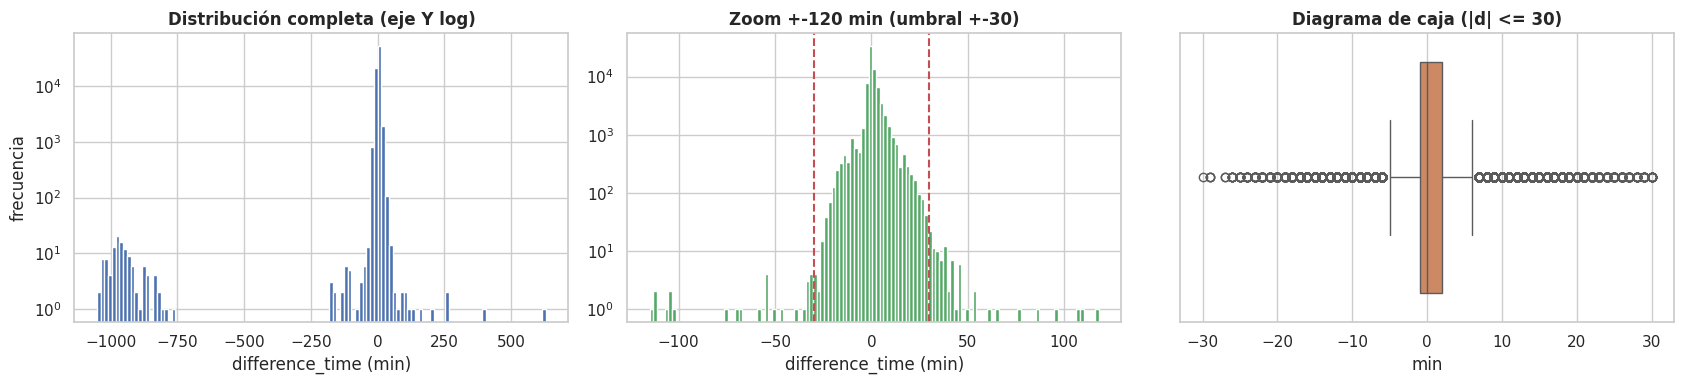

In [8]:
y = obs["diff_raw"].dropna()
q = y.quantile([0, .001, .01, .05, .25, .5, .75, .95, .99, .999, 1])
display(q.to_frame("difference_time (min)").T)

Q1, Q3 = y.quantile([.25, .75]); IQR = Q3 - Q1
lo, hi = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
print(f"Regla IQR (1.5·IQR): fuera de [{lo:.1f}, {hi:.1f}] -> {((y < lo) | (y > hi)).mean():.1%} de las observaciones")
print(f"Regla de dominio |d| > {OUTLIER_MIN} min -> {(y.abs() > OUTLIER_MIN).sum()} obs. ({(y.abs() > OUTLIER_MIN).mean():.2%})")

# ¿Los extremos son cruces de medianoche? Si lo fueran, sumar/restar 24 h (1440 min) devolvería un valor plausible
ext = obs[obs["diff_raw"].abs() > 120]
corr24 = ext["diff_raw"] + np.where(ext["diff_raw"] < 0, 1440, -1440)
print(f"|d| > 120 min: {len(ext)} obs. en {ext['lap_id'].nunique()} vueltas | tras corregir +-24 h, "
      f"dentro de +-{OUTLIER_MIN} min: {(corr24.abs() <= OUTLIER_MIN).mean():.1%}")

# Sensibilidad al umbral
filas = []
for thr in [10, 15, 20, 30, 45, 60, 120]:
    z = y[y.abs() <= thr]
    filas.append({"umbral |d| <=": thr, "obs. eliminadas": int((y.abs() > thr).sum()), "% eliminado": round((y.abs() > thr).mean() * 100, 3),
                  "media": round(z.mean(), 3), "desv. estándar": round(z.std(), 3), "MAE vs. cero": round(z.abs().mean(), 3)})
display(pd.DataFrame(filas).set_index("umbral |d| <="))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].hist(y, bins=120, color="#4C72B0"); axes[0].set_yscale("log")
axes[0].set(title="Distribución completa (eje Y log)", xlabel="difference_time (min)", ylabel="frecuencia")
axes[1].hist(y[y.abs() <= 120], bins=121, color="#55A868"); axes[1].set_yscale("log")
axes[1].axvline(OUTLIER_MIN, color="r", ls="--"); axes[1].axvline(-OUTLIER_MIN, color="r", ls="--")
axes[1].set(title=f"Zoom +-120 min (umbral +-{OUTLIER_MIN})", xlabel="difference_time (min)")
sns.boxplot(x=y[y.abs() <= OUTLIER_MIN], ax=axes[2], color="#DD8452"); axes[2].set(title=f"Diagrama de caja (|d| <= {OUTLIER_MIN})", xlabel="min")
plt.tight_layout(); save_fig("atipicos"); plt.show()

**Decisión.** La regla IQR marca una proporción muy alta de datos: en un servicio real una desviación de 6–15 min es normal, así que no es apropiada para este objetivo (concentrado en 0, con cola larga legítima). Además, los extremos **no son simples cruces de medianoche** (la corrección de +-24 h casi nunca da valores plausibles): la hora real pertenece a otro servicio o vuelta, es decir, un error de registro. Se usa una **regla de dominio**: son **registros erróneos** las observaciones con `|difference_time| > 30 min` (≈0.3 %), que deja intacta la cola legítima (retrasos de 15–30 min). Se conservan `diff_raw` (valor original) y la bandera `is_outlier`; se crea `target` (`diff_raw` sin atípicos) y se invalida también su hora real para que no contamine variables derivadas. El umbral es el parámetro `OUTLIER_MIN`.

In [9]:
obs["is_outlier"] = obs["diff_raw"].abs() > OUTLIER_MIN
obs["target"] = obs["diff_raw"].where(~obs["is_outlier"])
obs["real_ts"] = obs["real_ts"].where(~obs["is_outlier"])
print(f"Atípicos marcados: {obs['is_outlier'].sum()} | objetivo válido: {obs['target'].notna().sum():,} de {len(obs):,} ({obs['target'].notna().mean():.1%})")

Atípicos marcados: 238 | objetivo válido: 76,742 de 84,726 (90.6%)


#### 3.1.5.- Limpieza de `Monitoring.csv`

Reglas de dominio (parametrizables): coordenadas dentro de una caja envolvente amplia de Cusco, `0 <= speed <= 100` (km/h) y `0 <= bearing <= 360`. Los registros fuera de rango y los duplicados por (vehículo, instante) se **excluyen**; además se verifica el solapamiento con `Times.csv`, necesario para integrar ambas fuentes.

In [10]:
mon = mon_raw.copy()
mon["date"] = pd.to_datetime(mon["date"])
mon["ts"] = mon["date"] + pd.to_timedelta(mon["time"])
mon["vehicle_id"] = mon["vehicle_id_id"].astype(str)

LAT_RANGE, LON_RANGE, SPEED_MAX = (-13.8, -13.3), (-72.2, -71.6), 100
bad = pd.DataFrame({
    "lat fuera de rango": ~mon["latitude"].between(*LAT_RANGE),
    "lon fuera de rango": ~mon["longitude"].between(*LON_RANGE),
    "velocidad fuera de [0,100]": ~mon["speed"].between(0, SPEED_MAX),
    "rumbo fuera de [0,360]": ~mon["bearing"].between(0, 360),
})
print("Nulos:", int(mon.isna().sum().sum()), "| id duplicados:", int(mon["id"].duplicated().sum()),
      "| filas duplicadas (sin id):", int(mon.drop(columns=["id", "ts"]).duplicated().sum()),
      "| duplicados (vehículo, ts):", int(mon.duplicated(["vehicle_id", "ts"]).sum()))
display(bad.sum().to_frame("registros fuera de rango").T)

mon_clean = mon[~bad.any(axis=1)].drop_duplicates(subset=["vehicle_id", "ts"]).copy()
print(f"Monitoring limpio: {len(mon_clean):,} de {len(mon):,} registros")

t_dates, m_dates = set(obs["date"].dt.date), set(mon["date"].dt.date)
print(f"Días en común con Times: {len(t_dates & m_dates)} de {len(t_dates)} | "
      f"vehículos en común: {len(set(obs['vehicle_id']) & set(mon['vehicle_id']))} de {obs['vehicle_id'].nunique()}")

Nulos: 0 | id duplicados: 0 | filas duplicadas (sin id): 6690 | duplicados (vehículo, ts): 6783


,lat fuera de rango,lon fuera de rango,"velocidad fuera de [0,100]","rumbo fuera de [0,360]"
registros fuera de rango,0,3,3,0


Monitoring limpio: 1,623,642 de 1,630,431 registros
Días en común con Times: 27 de 27 | vehículos en común: 45 de 45


### 3.2.- Transformación de variables

Todas las predictoras de la observación `(vuelta, k)` usan **solo información disponible antes de que el vehículo llegue al punto `k`**. La hora real de llegada a `k` (`end_time`) **no** se usa: el objetivo se calcula directamente a partir de ella (fuga).

| Grupo | Variables |
|---|---|
| Autorregresivas | `lag1`, `lag2` (desviación en k−1 y k−2), `mean_prev` (media de la vuelta hasta k−1), `n_prev_valid`, `last_known` / `since_known` (último valor observado y cuántos puntos atrás) |
| Programación | `sched_gap_min` (min programados entre k−1 y k), `offset_min` (min desde el inicio de la vuelta), `lap_start_hour` |
| Temporales | `hour_sched`, `hour_sin/cos`, `dow_sin/cos`, `franja` (codificación cíclica, siguiendo a Kam et al.) |
| Operativas | `k`, `lap`, `vehicle_id`, `prev_lap_mean` (desviación media de la vuelta anterior del mismo vehículo, solo si ya terminó) |
| Monitoring | `mon_speed_mean`, `mon_zero_share`, `mon_n` (último tramo ya completado, ver abajo) |

In [11]:
d = obs.sort_values(["lap_id", "k"]).reset_index(drop=True).copy()
g_lap = d["lap_id"]

# --- Autorregresivas (solo puntos anteriores a k) ---
d["lag1"] = d.groupby("lap_id")["target"].shift(1)
d["lag2"] = d.groupby("lap_id")["target"].shift(2)
v = d["target"].fillna(0.0); n_ok = d["target"].notna().astype(int)
d["n_prev_valid"] = n_ok.groupby(g_lap).cumsum() - n_ok
d["mean_prev"] = ((v.groupby(g_lap).cumsum() - v) / d["n_prev_valid"]).where(d["n_prev_valid"] > 0)
d["last_known"] = d.groupby("lap_id")["target"].ffill().groupby(g_lap).shift(1)
last_idx = d["k"].where(d["target"].notna()).groupby(g_lap).ffill().groupby(g_lap).shift(1)
d["since_known"] = d["k"] - last_idx

# --- Programación (el horario programado se conoce de antemano) ---
d["sched_gap_min"] = d["sched_step_min"].where(~d["sched_disorder"] & (d["sched_step_min"] >= 0))
first_sched = d.groupby("lap_id")["sched_ts"].transform("first")
d["offset_min"] = ((d["sched_ts"] - first_sched).dt.total_seconds() / 60).where(~d["sched_disorder"])
d["lap_start_hour"] = first_sched.dt.hour + first_sched.dt.minute / 60

# --- Temporales (codificación cíclica) ---
d["hour_sin"] = np.sin(2 * np.pi * d["hour_sched"] / 24); d["hour_cos"] = np.cos(2 * np.pi * d["hour_sched"] / 24)
d["dow_sin"] = np.sin(2 * np.pi * d["dow"] / 7);          d["dow_cos"] = np.cos(2 * np.pi * d["dow"] / 7)
d["lap"] = d["lap"].astype(int)

# --- Vuelta anterior del mismo vehículo y día (solo si ya terminó antes de iniciar la actual) ---
lap_tbl = d.groupby("lap_id").agg(vehicle_id=("vehicle_id", "first"), date=("date", "first"), start=("sched_ts", "first"),
                                  mean_dev=("target", "mean"), last_real=("real_ts", "max")).sort_values(["vehicle_id", "date", "start"])
grp = lap_tbl.groupby(["vehicle_id", "date"])
lap_tbl["prev_lap_mean"] = grp["mean_dev"].shift(1)
lap_tbl.loc[grp["last_real"].shift(1) > lap_tbl["start"], "prev_lap_mean"] = np.nan    # la anterior aún no terminaba
d["prev_lap_mean"] = d["lap_id"].map(lap_tbl["prev_lap_mean"])

# --- Verificación anti-fuga: lag1/lag2 deben coincidir con el objetivo de los puntos k-1 y k-2 ---
muestra = d[d["k"] >= 3].sample(2000, random_state=SEED)
w = d.set_index(["lap_id", "k"])["target"]
for lag, col in [(1, "lag1"), (2, "lag2")]:
    ref = w.reindex(list(zip(muestra["lap_id"], muestra["k"] - lag))).to_numpy()
    assert np.allclose(muestra[col].to_numpy(), ref, equal_nan=True), f"{col} no coincide con el objetivo en k-{lag}"
print("Verificación anti-fuga: lag1 y lag2 coinciden con el objetivo en k-1 y k-2 (sin información de k).")

Verificación anti-fuga: lag1 y lag2 coinciden con el objetivo en k-1 y k-2 (sin información de k).


**Integración con `Monitoring`.** Para cada `(vuelta, k)` se resume el comportamiento del vehículo en el **último tramo ya completado**, entre la hora real de llegada a `k−2` y a `k−1`: es el tramo más reciente que el sistema conoce cuando el vehículo sale de `k−1`, de modo que no hay fuga (usar `k−1 → k` incorporaría la propia llegada a `k`). La unión es por **vehículo + ventana de tiempo** (la numeración de `lap` difiere entre archivos) y se vectoriza (sumas acumuladas + `searchsorted`) para escalar a ~1.6 M de registros.

In [12]:
def add_monitoring_features(d, mon):
    """Velocidad media / proporción de velocidad cero / nº de registros de Monitoring en la ventana [real(k-2), real(k-1)]."""
    out = d.copy()
    t1 = out.groupby("lap_id")["real_ts"].shift(1)
    t2 = out.groupby("lap_id")["real_ts"].shift(2)
    ok = t1.notna() & t2.notna() & (t2 < t1)

    codes, uniques = pd.factorize(pd.concat([mon["vehicle_id"], out["vehicle_id"]]))
    veh_map = dict(zip(uniques, range(len(uniques))))
    epoch = lambda s: ((s - pd.Timestamp("1970-01-01")) // pd.Timedelta("1s"))
    BIG = 10 ** 10                                      # separa vehículos en una única clave ordenable

    m = mon.assign(key=mon["vehicle_id"].map(veh_map).astype("int64") * BIG + epoch(mon["ts"]).astype("int64")).sort_values("key")
    keys = m["key"].to_numpy()
    cs_speed = np.concatenate([[0.0], np.cumsum(m["speed"].to_numpy(dtype=float))])
    cs_zero = np.concatenate([[0.0], np.cumsum((m["speed"].to_numpy() == 0).astype(float))])

    vcode = out["vehicle_id"].map(veh_map).astype("int64").to_numpy() * BIG
    lo_t = np.where(ok, epoch(t2.where(ok, pd.Timestamp("1970-01-01"))).astype("int64"), 0)
    hi_t = np.where(ok, epoch(t1.where(ok, pd.Timestamp("1970-01-01"))).astype("int64"), 0)
    lo = np.searchsorted(keys, vcode + lo_t, side="left")
    hi = np.searchsorted(keys, vcode + hi_t, side="right")
    n = np.where(ok, hi - lo, 0)
    with np.errstate(invalid="ignore", divide="ignore"):
        out["mon_speed_mean"] = np.where(n > 0, (cs_speed[hi] - cs_speed[lo]) / n, np.nan)
        out["mon_zero_share"] = np.where(n > 0, (cs_zero[hi] - cs_zero[lo]) / n, np.nan)
    out["mon_n"] = n
    return out

d = add_monitoring_features(d, mon_clean)
MON_COVERAGE = (d["mon_n"] > 0).mean()
USE_MON_FEATURES = MON_COVERAGE >= 0.20          # solo se usan si hay cobertura suficiente
print(f"Observaciones con al menos un registro de Monitoring en la ventana: {MON_COVERAGE:.1%} | se incluyen en los modelos: {USE_MON_FEATURES}")
d[["lap_id", "k", "target", "lag1", "lag2", "mean_prev", "last_known", "sched_gap_min", "prev_lap_mean",
   "mon_n", "mon_speed_mean", "mon_zero_share"]].iloc[18:26]

Observaciones con al menos un registro de Monitoring en la ventana: 78.4% | se incluyen en los modelos: True


,lap_id,k,target,lag1,lag2,mean_prev,last_known,sched_gap_min,prev_lap_mean,mon_n,mon_speed_mean,mon_zero_share
18,6654,1,-1.0,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN
19,6654,2,-2.0,-1.0,NaN,-1.000000,-1.0,2.0,NaN,0,NaN,NaN
20,6654,3,-3.0,-2.0,-1.0,-1.500000,-2.0,9.0,NaN,2,32.000000,0.0
21,6654,4,-4.0,-3.0,-2.0,-2.000000,-3.0,14.0,NaN,17,28.294118,0.0
22,6654,5,-8.0,-4.0,-3.0,-2.500000,-4.0,11.0,NaN,23,37.086957,0.0
23,6654,6,-12.0,-8.0,-4.0,-3.600000,-8.0,16.0,NaN,13,34.307692,0.0
24,6654,7,-13.0,-12.0,-8.0,-5.000000,-12.0,1.0,NaN,17,19.941176,0.0
25,6654,8,-12.0,-13.0,-12.0,-6.142857,-13.0,6.0,NaN,1,16.000000,0.0


### 3.3.- Partición cronológica (train / validación / test)

La partición es **por fecha** (semanas completas), no aleatoria, y todas las observaciones de una vuelta quedan en el mismo conjunto. Se trabaja con `k ≥ 2` y objetivo válido. El conjunto de *test* se reserva y se usa una sola vez (sección 6).

In [13]:
d["split"] = np.select([d["date"] <= TRAIN_END, d["date"] <= VAL_END], ["train", "val"], default="test")
model_df = d[(d["k"] >= 2) & d["target"].notna()].copy()

order = ["train", "val", "test"]
lap_first = d.drop_duplicates("lap_id")
lap_sp = lap_first["split"]
part = pd.DataFrame({
    "vueltas": lap_sp.value_counts().reindex(order),
    "% vueltas": (lap_sp.value_counts(normalize=True).reindex(order) * 100).round(1),
    "observaciones del modelo": model_df["split"].value_counts().reindex(order),
    "fecha inicio": d.groupby("split")["date"].min().reindex(order).dt.date,
    "fecha fin": d.groupby("split")["date"].max().reindex(order).dt.date,
})
display(part)
dnames = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
display(pd.crosstab(lap_first["split"], lap_first["dow"].map(dict(enumerate(dnames)))).reindex(index=order, columns=dnames).rename_axis("vueltas por día"))
assert d.groupby("lap_id")["split"].nunique().max() == 1          # ninguna vuelta cruza conjuntos
assert d.loc[d["split"] == "train", "date"].max() < d.loc[d["split"] == "val", "date"].min() < d.loc[d["split"] == "test", "date"].min()

,vueltas,% vueltas,observaciones del modelo,fecha inicio,fecha fin
split,,,,,
train,2382,50.6,36697,2025-01-06,2025-01-19
val,1192,25.3,18400,2025-01-20,2025-01-26
test,1133,24.1,17257,2025-01-27,2025-02-01


dow,Lun,Mar,Mié,Jue,Vie,Sáb,Dom
vueltas por día,,,,,,,
train,350,375,371,361,356,354,215
val,157,173,192,187,190,185,108
test,187,194,193,198,195,166,0


### 3.4.- Escalamiento, codificación e imputación

Los transformadores se **ajustan solo con *train*** (dentro de un `Pipeline`/`ColumnTransformer`) y luego se aplican a validación y prueba:

- **Modelos lineales y MLP:** imputación por mediana (+ indicador de faltante), `StandardScaler` para numéricas y *one-hot* para `vehicle_id`, `franja` y `dow`.
- **Árboles (RF, boosting):** sin escalamiento; imputación por mediana (RF) o `NaN` nativo (boosting) y codificación ordinal de las categóricas.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder

NUM_FEATURES = ["k", "lap", "hour_sched", "hour_sin", "hour_cos", "dow_sin", "dow_cos", "lap_start_hour",
                "sched_gap_min", "offset_min", "lag1", "lag2", "mean_prev", "n_prev_valid", "last_known", "since_known", "prev_lap_mean"]
if USE_MON_FEATURES:
    NUM_FEATURES += ["mon_speed_mean", "mon_zero_share", "mon_n"]
CAT_FEATURES = ["vehicle_id", "franja", "dow_cat"]
model_df["dow_cat"] = model_df["dow"].astype(str)
model_df["franja"] = model_df["franja"].astype(str)
FEATURES = NUM_FEATURES + CAT_FEATURES

train = model_df[model_df["split"] == "train"]; val = model_df[model_df["split"] == "val"]; test = model_df[model_df["split"] == "test"]
X_train, y_train = train[FEATURES], train["target"]; X_val, y_val = val[FEATURES], val["target"]
print(f"train {len(train):,} | val {len(val):,} | test {len(test):,} (reservado) | {len(FEATURES)} variables")

def prep_linear():
    num = Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", StandardScaler())])
    return ColumnTransformer([("num", num, NUM_FEATURES), ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES)])

def prep_tree(impute=True):
    num = SimpleImputer(strategy="median", add_indicator=True) if impute else "passthrough"
    return ColumnTransformer([("num", num, NUM_FEATURES),
                              ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT_FEATURES)])

# Demostración (ajustado solo con train): media y desviación de las numéricas antes y después de escalar
sc = StandardScaler().fit(X_train[NUM_FEATURES].fillna(X_train[NUM_FEATURES].median()))
Z = pd.DataFrame(sc.transform(X_train[NUM_FEATURES].fillna(X_train[NUM_FEATURES].median())), columns=NUM_FEATURES)
pd.concat({"antes": X_train[NUM_FEATURES].agg(["mean", "std"]).T.round(2), "después (train)": Z.agg(["mean", "std"]).T.round(2)}, axis=1)

train 36,697 | val 18,400 | test 17,257 (reservado) | 23 variables


antes        después (train)     
                 mean    std            mean  std
k                9.86   4.85             0.0  1.0
lap              2.79   1.40             0.0  1.0
hour_sched      13.08   4.30             0.0  1.0
hour_sin        -0.12   0.73            -0.0  1.0
hour_cos        -0.47   0.48             0.0  1.0
dow_sin          0.06   0.70            -0.0  1.0
dow_cos         -0.04   0.71             0.0  1.0
lap_start_hour  11.72   4.23            -0.0  1.0
sched_gap_min    9.47   6.73            -0.0  1.0
offset_min      81.37  44.91             0.0  1.0
lag1             0.60   4.46            -0.0  1.0
lag2             0.56   4.38            -0.0  1.0
mean_prev       -0.18   2.24             0.0  1.0
n_prev_valid     8.62   4.84            -0.0  1.0
last_known       0.70   4.60            -0.0  1.0
since_known      1.02   0.18            -0.0  1.0
prev_lap_mean    0.04   3.45            -0.0  1.0
mon_speed_mean  23.67   5.76            -0.0  1.0
mon_zero_share   0.00   0.03             0.0  1.0
mon_n           15.48  15.12            -0.0  1.0

## 4.- Análisis exploratorio de datos (EDA)

Se realiza sobre los datos ya limpios (sección 3.1), para describir el comportamiento real del servicio y justificar las variables de la sección 3.2.

### 4.1.- Estadísticos descriptivos

In [15]:
n_null, n_out = int(obs["diff_missing"].sum()), int(obs["is_outlier"].sum())
embudo = pd.Series({
    "Vueltas (filas de Times.csv)": len(times_raw),
    "Observaciones tras expandir (18 por vuelta)": len(obs),
    "(−) con difference_time nulo": n_null,
    "(−) atípicas (|d| > 30 min)": n_out,
    "= Observaciones con objetivo válido": int(obs["target"].notna().sum()),
    "Observaciones del modelo (k ≥ 2, objetivo válido)": len(model_df),
    "Vehículos / días": f"{obs['vehicle_id'].nunique()} / {obs['date'].nunique()}",
}, name="valor").to_frame()
display(embudo)

t = obs["target"].dropna()
desc = t.describe(percentiles=[.05, .25, .5, .75, .95]).to_frame("difference_time (limpia)")
desc.loc["asimetría"] = t.skew(); desc.loc["curtosis"] = t.kurt()
desc.loc["% = 0"] = (t == 0).mean() * 100; desc.loc["% < 0 (adelantado)"] = (t < 0).mean() * 100; desc.loc["% > 0 (atrasado)"] = (t > 0).mean() * 100
display(desc.round(3))

por_k = obs.groupby("k")["target"].agg(n="count", media="mean", mediana="median", desv="std", MAE_vs_cero=lambda s: s.abs().mean()).round(2)
por_k["% nulo/atípico"] = (obs.groupby("k")["target"].apply(lambda s: s.isna().mean()) * 100).round(1)
por_k

,valor
Vueltas (filas de Times.csv),4707
Observaciones tras expandir (18 por vuelta),84726
(−) con difference_time nulo,7746
(−) atípicas (|d| > 30 min),238
= Observaciones con objetivo válido,76742
"Observaciones del modelo (k ≥ 2, objetivo válido)",72354
Vehículos / días,45 / 27


,difference_time (limpia)
count,76742.000
mean,0.861
std,4.975
min,-30.000
5%,-5.000
25%,-1.000
50%,0.000
75%,2.000
95%,10.000
max,30.000


,n,media,mediana,desv,MAE_vs_cero,% nulo/atípico
k,,,,,,
1,4388,-0.66,0.0,1.48,0.80,6.8
2,4427,-1.32,-1.0,1.58,1.35,5.9
3,4135,-1.03,-1.0,1.22,1.16,12.2
4,4423,-0.12,0.0,1.51,0.90,6.0
5,4394,-0.28,0.0,2.43,1.50,6.6
6,4381,0.94,1.0,4.13,2.74,6.9
7,4396,0.32,0.0,4.08,2.49,6.6
8,4411,1.23,1.0,4.30,2.92,6.3
9,4400,0.76,0.0,4.11,2.57,6.5


### 4.2.- Distribuciones y relaciones entre variables

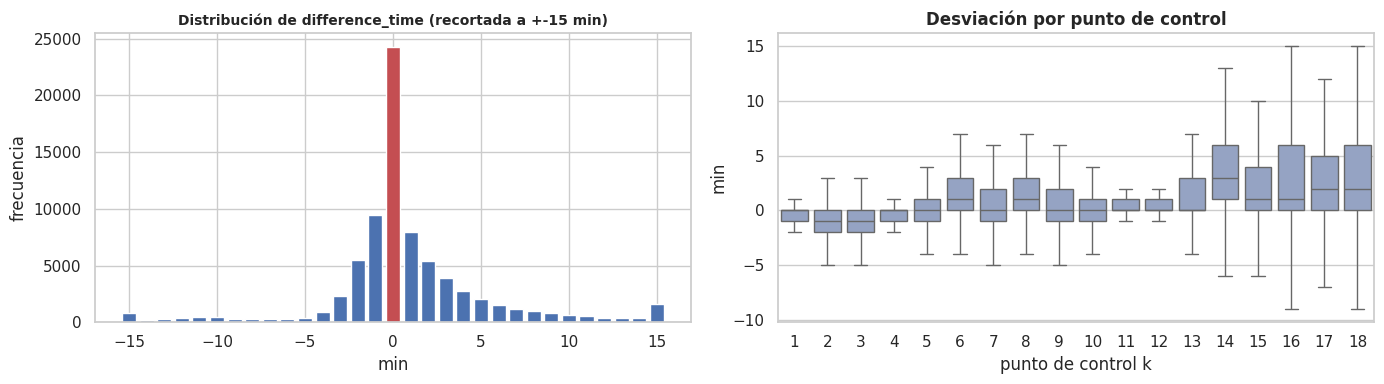

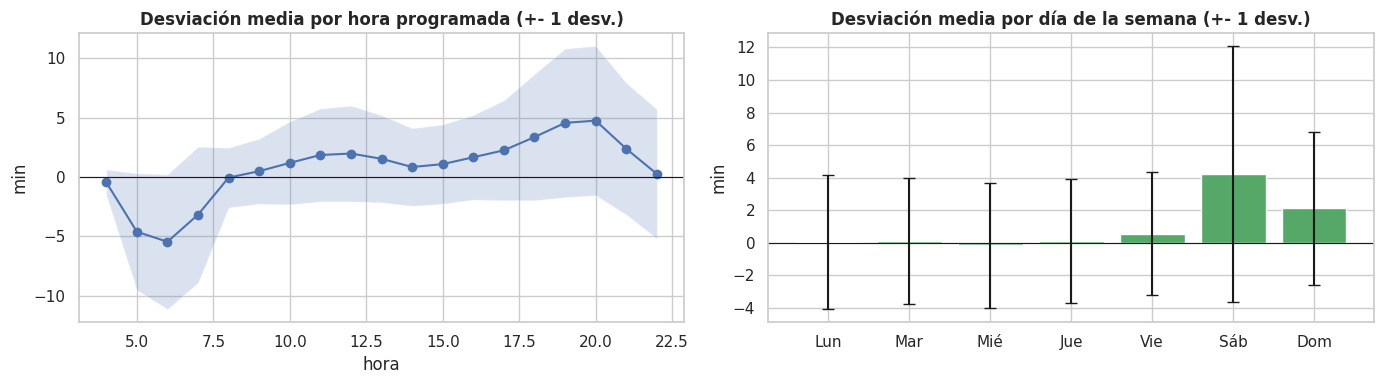

Correlación de la desviación en k con la de k-1 y k-2: {'y_k-1': 0.914, 'y_k-2': 0.849}


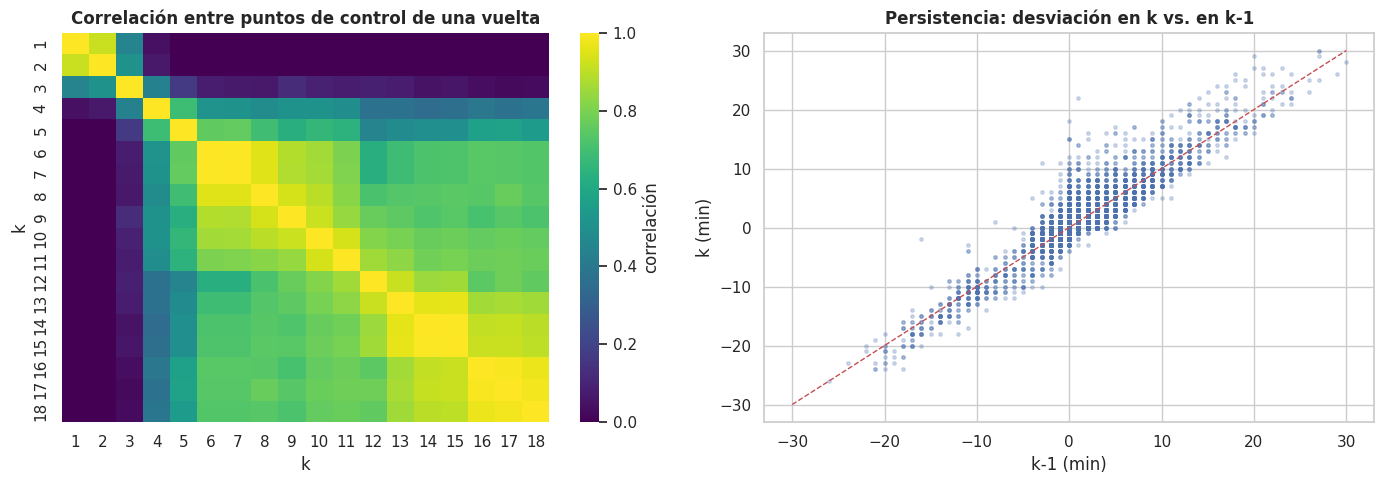

In [16]:
d_ok = d.dropna(subset=["target"]).copy()
d_ok["hour"] = d_ok["sched_ts"].dt.hour

# (a) Distribución del objetivo y desviación por punto de control
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
vc = t.clip(-15, 15).value_counts().sort_index()
axes[0].bar(vc.index, vc.values, color=["#C44E52" if i == 0 else "#4C72B0" for i in vc.index])
axes[0].set_title("Distribución de difference_time (recortada a +-15 min)", fontsize=10); axes[0].set(xlabel="min", ylabel="frecuencia")
sns.boxplot(data=d_ok, x="k", y="target", showfliers=False, ax=axes[1], color="#8DA0CB")
axes[1].set(title="Desviación por punto de control", xlabel="punto de control k", ylabel="min")
plt.tight_layout(); save_fig("eda_objetivo_k"); plt.show()

# (b) Efectos temporales: hora programada y día de la semana
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
h = d_ok.groupby("hour")["target"].agg(["mean", "std", "count"]); h = h[h["count"] >= 100]
axes[0].plot(h.index, h["mean"], marker="o", color="#4C72B0"); axes[0].fill_between(h.index, h["mean"] - h["std"], h["mean"] + h["std"], alpha=.2)
axes[0].axhline(0, color="k", lw=.8); axes[0].set(title="Desviación media por hora programada (+- 1 desv.)", xlabel="hora", ylabel="min")
w_ = d_ok.groupby("dow")["target"].agg(["mean", "std"])
axes[1].bar([dnames[i] for i in w_.index], w_["mean"], yerr=w_["std"], capsize=4, color="#55A868")
axes[1].axhline(0, color="k", lw=.8); axes[1].set(title="Desviación media por día de la semana (+- 1 desv.)", ylabel="min")
plt.tight_layout(); save_fig("eda_hora_dia"); plt.show()

# (c) Dependencia entre puntos consecutivos (autocorrelación)
wide = obs.pivot(index="lap_id", columns="k", values="target")
corr_k = wide.corr(min_periods=500)
lag = pd.DataFrame({"y_k": wide.stack(), "y_k-1": wide.shift(1, axis=1).stack(), "y_k-2": wide.shift(2, axis=1).stack()}).dropna()
print("Correlación de la desviación en k con la de k-1 y k-2:", lag.corr().iloc[0, 1:].round(3).to_dict())
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(corr_k, cmap="viridis", vmin=0, vmax=1, ax=axes[0], cbar_kws={"label": "correlación"})
axes[0].set(title="Correlación entre puntos de control de una vuelta", xlabel="k", ylabel="k")
sm = lag.sample(min(8000, len(lag)), random_state=SEED)
axes[1].scatter(sm["y_k-1"], sm["y_k"], s=6, alpha=.25, color="#4C72B0"); axes[1].plot([-30, 30], [-30, 30], "r--", lw=1)
axes[1].set(title="Persistencia: desviación en k vs. en k-1", xlabel="k-1 (min)", ylabel="k (min)")
plt.tight_layout(); save_fig("eda_autocorrelacion"); plt.show()

**Lectura.** La desviación **cambia de signo durante el día** (adelantos en las primeras horas, retrasos desde la tarde), **crece con el punto de control** (los retrasos se acumulan) y el **sábado** se comporta distinto; esto justifica incluir hora, día y `k`. Además hay una **fuerte dependencia entre puntos consecutivos** (correlación ≈ 0.9): lo ocurrido en el punto anterior es el mejor predictor del siguiente, lo que respalda la *persistencia* como referencia exigente y los rezagos como predictoras.

## 5.- Modelado y evaluación

### 5.1.- Métricas de evaluación

Métrica principal: **MAE** (minutos). Complementarias: RMSE, R² y el porcentaje de predicciones con error absoluto <= 1 y <= 2 min (no se usa MAPE porque el objetivo vale 0 en cerca del 29 % de los casos). Todo se evalúa sobre **validación**; *test* permanece sin usar.

In [17]:
def metrics(y, yhat):
    y = np.asarray(y, float); yhat = np.asarray(yhat, float); e = y - yhat
    return {"n": len(y), "MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e ** 2)),
            "R2": 1 - np.sum(e ** 2) / np.sum((y - y.mean()) ** 2),
            "% err <=1 min": np.mean(np.abs(e) <= 1) * 100, "% err <=2 min": np.mean(np.abs(e) <= 2) * 100}

RESULTS, PRED_VAL = {}, {}          # nombre -> métricas / predicciones en validación

def register(name, yhat, mask=None):
    yv, yh = y_val.to_numpy(), np.asarray(yhat, float)
    if mask is not None: yv, yh = yv[mask], yh[mask]
    RESULTS[name] = metrics(yv, yh)
    if mask is None: PRED_VAL[name] = yh

### 5.2.- Modelos de referencia (baselines)

1. **Cero:** el vehículo llega a la hora programada.
2. **Persistencia estricta:** `ŷ_k = y_{k−1}`; solo evaluable donde existe `lag1` (su `n` es menor).
3. **Persistencia (último valor conocido):** `ŷ_k` = última desviación observada antes de `k` (0 si no hay ninguna); cubre todas las observaciones y es la referencia comparable con los modelos. **Su MAE es el umbral mínimo que debe superar cualquier modelo.**
4. **Promedio histórico:** media de *train* por (punto de control, franja horaria).

In [18]:
BASELINES = ["Cero", "Persistencia estricta (k-1) [solo con lag1]", "Persistencia (último valor conocido)", "Promedio histórico (k, franja)"]
register("Cero", np.zeros(len(val)))
register(BASELINES[1], val["lag1"].to_numpy(), mask=val["lag1"].notna().to_numpy())
register("Persistencia (último valor conocido)", val["last_known"].fillna(0).to_numpy())

hist = train.groupby(["k", "franja"])["target"].mean(); hist_k = train.groupby("k")["target"].mean()
hist_pred = pd.Series([hist.get(kk, np.nan) for kk in zip(val["k"], val["franja"])]).fillna(val["k"].map(hist_k)).to_numpy()
register("Promedio histórico (k, franja)", hist_pred)

pd.DataFrame({n: RESULTS[n] for n in BASELINES}).T.astype({"n": int}).round(3)

,n,MAE,RMSE,R2,% err <=1 min,% err <=2 min
Cero,18400,3.131,5.527,-0.052,51.380,65.533
Persistencia estricta (k-1) [solo con lag1],18020,1.415,2.146,0.834,66.210,84.517
Persistencia (último valor conocido),18400,1.431,2.190,0.835,65.750,84.261
"Promedio histórico (k, franja)",18400,2.760,4.360,0.345,32.929,56.870


### 5.3.- Hiperparámetros y estrategia de ajuste

Modelos: **Ridge**, **Lasso**, **Random Forest**, **gradient boosting** (`HistGradientBoostingRegressor` y, si están instalados, **LightGBM** y **XGBoost**) y **MLP** (`MLPRegressor`). 

> **Aclaración Metodológica sobre MLP:** A diferencia de lo formulado preliminarmente en el Entregable 1 (donde se mencionó teóricamente *dropout*), `sklearn.neural_network.MLPRegressor` no implementa regularización por dropout; la regularización se implementa rigurosamente mediante decaimiento de pesos $L_2$ (`alpha`), optimizador Adam con tasa adaptativa (`learning_rate_init`) y parada temprana (`early_stopping=True`) sobre un subconjunto interno de validación del 10%.

Los modelos de boosting usan pérdida **L1 (MAE)**, alineada con la métrica principal. El ajuste es una **búsqueda aleatoria** (`RandomizedSearchCV`) con **validación cruzada temporal de ventana expansiva por días** sobre *train* (un día nunca se parte entre entrenamiento y validación) y MAE como criterio.

In [19]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from scipy.stats import loguniform

class DayExpandingSplit:
    """Ventana expansiva por días: el pliegue i entrena con los primeros días y valida con el bloque de días siguiente."""
    def __init__(self, dates, n_splits=4, min_train_days=6):
        self.days = pd.to_datetime(np.asarray(dates)).normalize().to_numpy(); self.n_splits = n_splits; self.min_train = min_train_days
    def split(self, X=None, y=None, groups=None):
        ud = np.unique(self.days); blk = (len(ud) - self.min_train) // self.n_splits
        for i in range(self.n_splits):
            tr = ud[: self.min_train + i * blk]; te = ud[self.min_train + i * blk: self.min_train + (i + 1) * blk]
            yield np.where(np.isin(self.days, tr))[0], np.where(np.isin(self.days, te))[0]
    def get_n_splits(self, *a, **k): return self.n_splits

cv = list(DayExpandingSplit(train["date"], n_splits=CV_SPLITS, min_train_days=MIN_TRAIN_DAYS).split())
print("Pliegues (obs. entrenamiento / obs. validación):", [(len(a), len(b)) for a, b in cv])

N_JOBS = -1
models = {   # nombre -> (pipeline, espacio de búsqueda, nº de iteraciones)
    "Ridge": (Pipeline([("prep", prep_linear()), ("m", Ridge(random_state=SEED))]), {"m__alpha": loguniform(1e-2, 1e3)}, N_ITER),
    "Lasso": (Pipeline([("prep", prep_linear()), ("m", Lasso(max_iter=3000, tol=1e-3, random_state=SEED))]), {"m__alpha": loguniform(1e-3, 1e0)}, N_ITER),
    "Random Forest": (Pipeline([("prep", prep_tree()), ("m", RandomForestRegressor(random_state=SEED, n_jobs=N_JOBS))]),
                      {"m__n_estimators": [100, 150], "m__max_depth": [8, 12, 16, None], "m__min_samples_leaf": [3, 5, 10, 20],
                       "m__max_features": [0.3, 0.5, 0.7, 1.0]}, N_ITER),
    "HistGradientBoosting (L1)": (Pipeline([("prep", prep_tree(impute=False)), ("m", HistGradientBoostingRegressor(loss="absolute_error", random_state=SEED))]),
                      {"m__learning_rate": [0.03, 0.05, 0.1], "m__max_leaf_nodes": [15, 31, 63], "m__min_samples_leaf": [20, 50, 100],
                       "m__l2_regularization": [0, 1, 10], "m__max_iter": [200, 400]}, N_ITER),
    "MLP": (Pipeline([("prep", prep_linear()), ("m", MLPRegressor(early_stopping=True, max_iter=200, random_state=SEED))]),
            {"m__hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64)], "m__alpha": loguniform(1e-5, 1e-1),
             "m__learning_rate_init": loguniform(1e-3, 1e-2)}, N_ITER),
}
if lgb is not None:
    models["LightGBM (L1)"] = (Pipeline([("prep", prep_tree(impute=False)), ("m", lgb.LGBMRegressor(objective="regression_l1", random_state=SEED, n_jobs=N_JOBS, verbose=-1))]),
        {"m__learning_rate": [0.03, 0.05, 0.1], "m__num_leaves": [15, 31, 63], "m__min_child_samples": [20, 50, 100],
         "m__reg_lambda": [0, 1, 10], "m__n_estimators": [200, 400]}, N_ITER)
if xgb is not None:
    models["XGBoost (L1)"] = (Pipeline([("prep", prep_tree(impute=False)), ("m", xgb.XGBRegressor(objective="reg:absoluteerror", random_state=SEED, n_jobs=N_JOBS, tree_method="hist"))]),
        {"m__learning_rate": [0.03, 0.05, 0.1], "m__max_depth": [4, 6, 8], "m__min_child_weight": [1, 5, 20],
         "m__reg_lambda": [1, 10], "m__n_estimators": [200, 400]}, N_ITER)

fmt = lambda v: v if isinstance(v, list) else f"{v.dist.name}{tuple(round(a, 5) for a in v.args)}"
display(pd.Series({n: {k.replace("m__", ""): fmt(v) for k, v in sp.items()} for n, (_, sp, _) in models.items()}, name="espacio de búsqueda").to_frame())

Pliegues (obs. entrenamiento / obs. validación): [(16750, 4297), (21047, 5868), (26915, 5530), (32445, 4252)]


,espacio de búsqueda
Ridge,"{'alpha': 'loguniform(0.01, 1000.0)'}"
Lasso,"{'alpha': 'loguniform(0.001, 1.0)'}"
Random Forest,"{'n_estimators': [100, 150], 'max_depth': [8, ..."
HistGradientBoosting (L1),"{'learning_rate': [0.03, 0.05, 0.1], 'max_leaf..."
MLP,"{'hidden_layer_sizes': [(32,), (64,), (64, 32)..."
LightGBM (L1),"{'learning_rate': [0.03, 0.05, 0.1], 'num_leav..."
XGBoost (L1),"{'learning_rate': [0.03, 0.05, 0.1], 'max_dept..."


### 5.4.- Entrenamiento y resultados por modelo

In [20]:
FITTED, TUNING = {}, []
t0 = time.time()
for name, (pipe, space, n_iter) in models.items():
    ts = time.time()
    if RUN_TUNING:
        grid = int(np.prod([len(v) for v in space.values()])) if all(isinstance(v, list) for v in space.values()) else n_iter
        search = RandomizedSearchCV(pipe, space, n_iter=min(n_iter, grid), cv=cv, scoring="neg_mean_absolute_error",
                                    random_state=SEED, n_jobs=1, refit=True).fit(X_train, y_train)
        best, i = search.best_estimator_, search.best_index_
        folds = [-search.cv_results_[f"split{j}_test_score"][i] for j in range(len(cv))]
        TUNING.append({"modelo": name, "mejores hiperparámetros": {k.replace("m__", ""): v for k, v in search.best_params_.items()},
                       "MAE CV (media)": np.mean(folds), "MAE CV (desv.)": np.std(folds), "tiempo (s)": round(time.time() - ts, 1)})
    else:
        best = pipe.fit(X_train, y_train)
    FITTED[name] = best
    register(name, best.predict(X_val))
    print(f"{name:<28} MAE val = {RESULTS[name]['MAE']:.3f}   ({time.time() - ts:.0f}s)")
print(f"Tiempo total: {time.time() - t0:.0f}s")

ML_NAMES = list(models)
print("\nResultados por modelo en validación:")
display(pd.DataFrame({n: RESULTS[n] for n in ML_NAMES}).T.astype({"n": int}).sort_values("MAE").round(3))
if TUNING:
    pd.set_option("display.max_colwidth", 130)
    print("Resultados del ajuste de hiperparámetros (validación cruzada temporal sobre train):")
    display(pd.DataFrame(TUNING).set_index("modelo").round(3))

Ridge                        MAE val = 1.421   (6s)
Lasso                        MAE val = 1.428   (16s)
Random Forest                MAE val = 0.943   (417s)
HistGradientBoosting (L1)    MAE val = 0.905   (76s)
MLP                          MAE val = 1.022   (304s)
LightGBM (L1)                MAE val = 0.903   (57s)
XGBoost (L1)                 MAE val = 0.904   (94s)
Tiempo total: 970s

Resultados por modelo en validación:


,n,MAE,RMSE,R2,% err <=1 min,% err <=2 min
LightGBM (L1),18400,0.903,1.529,0.919,69.723,89.886
XGBoost (L1),18400,0.904,1.484,0.924,70.582,90.495
HistGradientBoosting (L1),18400,0.905,1.524,0.920,69.424,89.967
Random Forest,18400,0.943,1.520,0.920,68.826,89.777
MLP,18400,1.022,1.564,0.916,64.636,88.022
Ridge,18400,1.421,2.056,0.854,47.793,77.918
Lasso,18400,1.428,2.090,0.850,48.451,77.582


Resultados del ajuste de hiperparámetros (validación cruzada temporal sobre train):


,mejores hiperparámetros,MAE CV (media),MAE CV (desv.),tiempo (s)
modelo,,,,
Ridge,{'alpha': 0.0195172246414495},1.399,0.244,5.7
Lasso,{'alpha': 0.06251373574521749},1.394,0.228,15.8
Random Forest,"{'n_estimators': 100, 'min_samples_leaf': 3, 'max_features': 0.5, 'max_depth': None}",0.999,0.179,417.1
HistGradientBoosting (L1),"{'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_iter': 400, 'learning_rate': 0.1, 'l2_regularization': 0}",0.951,0.173,75.7
MLP,"{'alpha': 5.415244119402538e-05, 'hidden_layer_sizes': (128, 64), 'learning_rate_init': 0.004089339433965306}",1.095,0.151,303.8
LightGBM (L1),"{'reg_lambda': 10, 'num_leaves': 31, 'n_estimators': 200, 'min_child_samples': 50, 'learning_rate': 0.1}",0.947,0.172,56.5
XGBoost (L1),"{'reg_lambda': 1, 'n_estimators': 400, 'min_child_weight': 1, 'max_depth': 8, 'learning_rate': 0.05}",0.956,0.158,93.8


### 5.5.- Curvas de aprendizaje (pérdida)

Evidencian la convergencia y el posible sobreajuste de los modelos iterativos: **MLP** (pérdida de entrenamiento y R² en el subconjunto de validación interno del `early_stopping`) y **gradient boosting** (MAE en *train* y validación por iteración).

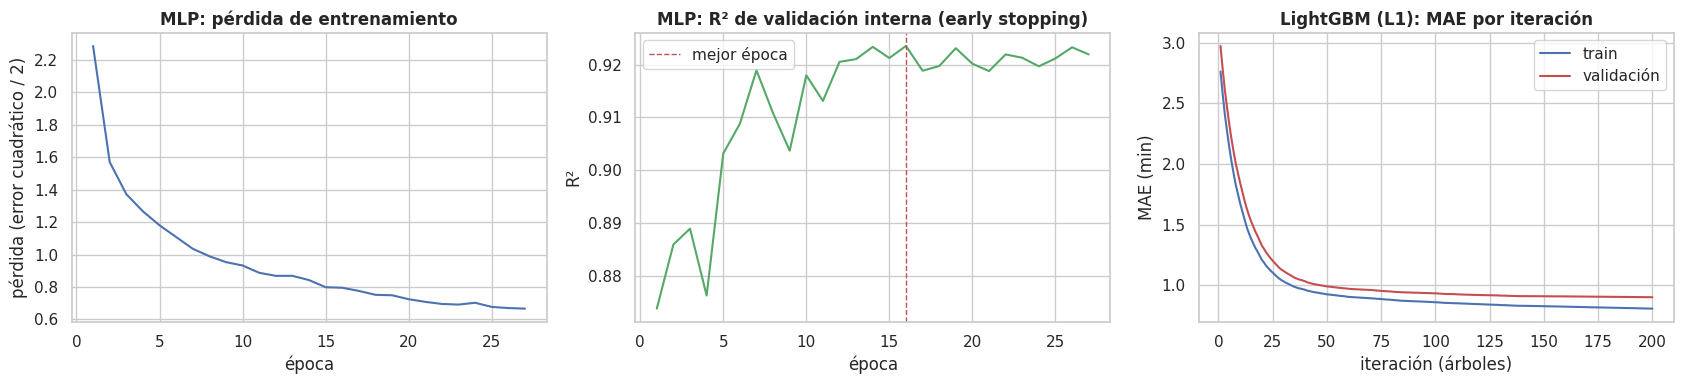

MLP: 27 épocas, mejor R² interno = 0.924 | LightGBM (L1): MAE final train = 0.809, validación = 0.903


In [21]:
from sklearn.base import clone

def boosting_curves(pipe, Xa, ya, Xb, yb):
    """MAE por iteración (conjunto A = entrenamiento, B = validación) de un pipeline de boosting ya ajustado."""
    prep, m = pipe.named_steps["prep"], pipe.named_steps["m"]
    A, B = prep.transform(Xa), prep.transform(Xb)
    cls = type(m).__name__
    if cls == "LGBMRegressor":
        m2 = clone(m).fit(A, ya, eval_set=[(A, ya), (B, yb)], eval_names=["train", "val"], eval_metric="l1")
        r = m2.evals_result_; return list(next(iter(r["train"].values()))), list(next(iter(r["val"].values())))
    if cls == "XGBRegressor":
        m2 = clone(m).fit(A, ya, eval_set=[(A, ya), (B, yb)], verbose=False)
        r = m2.evals_result(); return list(next(iter(r["validation_0"].values()))), list(next(iter(r["validation_1"].values())))
    mae_ = lambda y_, p_: float(np.mean(np.abs(np.asarray(y_) - p_)))      # HistGradientBoosting: predicciones por etapa
    return [mae_(ya, p) for p in m.staged_predict(A)], [mae_(yb, p) for p in m.staged_predict(B)]

# --- MLP: pérdida y R² por época ---
mlp = FITTED["MLP"].named_steps["m"]
# --- Boosting: MAE por iteración del mejor modelo de boosting en validación ---
BOOST = [n for n in ML_NAMES if any(s in n for s in ("LightGBM", "XGBoost", "HistGradientBoosting"))]
gb_name = min(BOOST, key=lambda n: RESULTS[n]["MAE"])
tr_c, va_c = boosting_curves(FITTED[gb_name], X_train, y_train, X_val, y_val)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot(range(1, len(mlp.loss_curve_) + 1), mlp.loss_curve_, color="#4C72B0")
axes[0].set(title="MLP: pérdida de entrenamiento", xlabel="época", ylabel="pérdida (error cuadrático / 2)")
axes[1].plot(range(1, len(mlp.validation_scores_) + 1), mlp.validation_scores_, color="#55A868")
axes[1].axvline(int(np.argmax(mlp.validation_scores_)) + 1, color="r", ls="--", lw=1, label="mejor época")
axes[1].set(title="MLP: R² de validación interna (early stopping)", xlabel="época", ylabel="R²"); axes[1].legend()
axes[2].plot(range(1, len(tr_c) + 1), tr_c, label="train", color="#4C72B0"); axes[2].plot(range(1, len(va_c) + 1), va_c, label="validación", color="#C44E52")
axes[2].set(title=f"{gb_name}: MAE por iteración", xlabel="iteración (árboles)", ylabel="MAE (min)"); axes[2].legend()
plt.tight_layout(); save_fig("curvas_aprendizaje"); plt.show()
print(f"MLP: {len(mlp.loss_curve_)} épocas, mejor R² interno = {mlp.best_validation_score_:.3f} | "
      f"{gb_name}: MAE final train = {tr_c[-1]:.3f}, validación = {va_c[-1]:.3f}")

### 5.6.- Comparación de modelos

,n,MAE,RMSE,R2,% err <=1 min,% err <=2 min
LightGBM (L1),18400,0.903,1.529,0.919,69.723,89.886
XGBoost (L1),18400,0.904,1.484,0.924,70.582,90.495
HistGradientBoosting (L1),18400,0.905,1.524,0.920,69.424,89.967
Random Forest,18400,0.943,1.520,0.920,68.826,89.777
MLP,18400,1.022,1.564,0.916,64.636,88.022
Persistencia estricta (k-1) [solo con lag1],18020,1.415,2.146,0.834,66.210,84.517
Ridge,18400,1.421,2.056,0.854,47.793,77.918
Lasso,18400,1.428,2.090,0.850,48.451,77.582
Persistencia (último valor conocido),18400,1.431,2.190,0.835,65.750,84.261
"Promedio histórico (k, franja)",18400,2.760,4.360,0.345,32.929,56.870


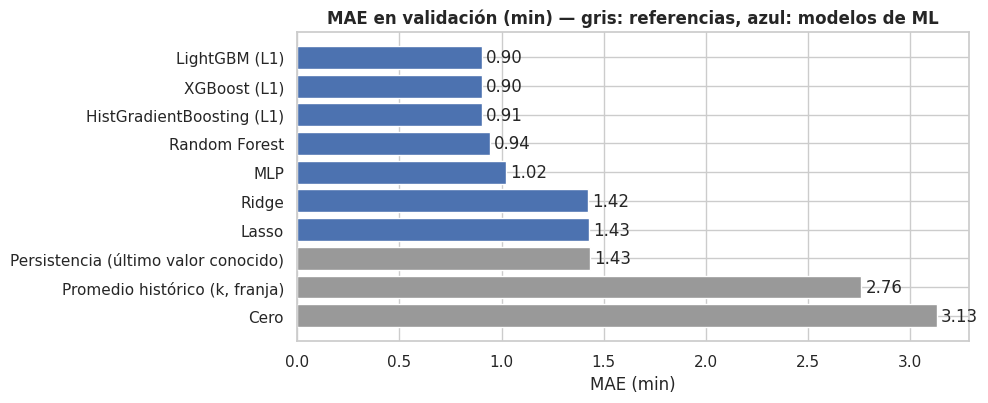

In [22]:
comp = pd.DataFrame(RESULTS).T.astype({"n": int}).sort_values("MAE")
display(comp.round(3))

main = comp[comp.index.isin(["Cero", "Persistencia (último valor conocido)", "Promedio histórico (k, franja)"] + ML_NAMES)]
is_base = [n in ("Cero", "Persistencia (último valor conocido)", "Promedio histórico (k, franja)") for n in main.index]
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(main.index[::-1], main["MAE"][::-1], color=["#999999" if b else "#4C72B0" for b in is_base[::-1]])
for i, v_ in enumerate(main["MAE"][::-1]): ax.text(v_ + .02, i, f"{v_:.2f}", va="center")
ax.set(title="MAE en validación (min) — gris: referencias, azul: modelos de ML", xlabel="MAE (min)")
plt.tight_layout(); save_fig("comparacion_modelos"); plt.show()

**Prueba de Wilcoxon pareada (Paso 4 del protocolo):** 
Para evaluar si la diferencia entre el mejor modelo de ML y las alternativas es estadísticamente significativa, se aplica la prueba de rangos con signo de Wilcoxon. 
*Nota metodológica:* Aplicar la prueba a nivel de observaciones individuales ($N=18,400$) incurre en **pseudoreplicación**, pues los 18 puntos de una misma vuelta están fuertemente autocorrelacionados ($ho pprox 0.914$). Por ello, además del contraste por observación, se realiza la **comparación agregada por vuelta** (promediando los errores absolutos de cada vuelta completa, $N=1,192$ vueltas en validación), garantizando independencia muestral entre unidades experimentales.

In [23]:
from scipy.stats import wilcoxon

best_name = min(ML_NAMES, key=lambda n: RESULTS[n]["MAE"])
print("Mejor modelo de ML en validación:", best_name, f"(MAE = {RESULTS[best_name]['MAE']:.3f})")

abs_err = {n: np.abs(y_val.to_numpy() - PRED_VAL[n]) for n in PRED_VAL}
val_df_eval = val.copy()
for n in PRED_VAL: val_df_eval[f"ae_{n}"] = abs_err[n]

# Comparación por observación y por vuelta completa (eliminando pseudoreplicación)
filas = []
for n, err in abs_err.items():
    if n == best_name: continue
    # 1. Por observación
    p_obs = wilcoxon(abs_err[best_name], err).pvalue
    # 2. Por vuelta (agrupada)
    lap_mae_best = val_df_eval.groupby("lap_id")[f"ae_{best_name}"].mean()
    lap_mae_ref = val_df_eval.groupby("lap_id")[f"ae_{n}"].mean()
    p_lap = wilcoxon(lap_mae_best, lap_mae_ref).pvalue
    pct_beat = (lap_mae_best < lap_mae_ref).mean() * 100
    
    filas.append({
        "comparación": f"{best_name} vs. {n}",
        "ΔMAE": RESULTS[best_name]["MAE"] - RESULTS[n]["MAE"],
        "p-val (obs)": p_obs,
        "p-val (vuelta)": p_lap,
        "% vueltas ganadas": pct_beat,
        "significativo (α=0.05)": p_lap < 0.05
    })

comp_stat = pd.DataFrame(filas).set_index("comparación")
display(comp_stat.round(4))
save_tab(comp_stat, "comparacion_wilcoxon_validacion")

Mejor modelo de ML en validación: LightGBM (L1) (MAE = 0.903)


                                                        ΔMAE  p-val (obs)  p-val (vuelta)  % vueltas ganadas  significativo (α=0.05)
comparación                                                                                                                         
LightGBM (L1) vs. Cero                               -2.2280      0.0e+00         0.0e+00             100.00                    True
LightGBM (L1) vs. Promedio histórico (k, franja)     -1.8570      0.0e+00         0.0e+00              98.15                    True
LightGBM (L1) vs. Persistencia (último valor)        -0.5278      0.0e+00        2.45e-152             93.45                    True
LightGBM (L1) vs. Lasso                              -0.5243      0.0e+00        4.12e-151             92.87                    True
LightGBM (L1) vs. Ridge                              -0.5178      0.0e+00        1.08e-150             92.95                    True
LightGBM (L1) vs. MLP                                -0.1190     6.3e

### 5.7.- Análisis de errores del mejor modelo (validación)

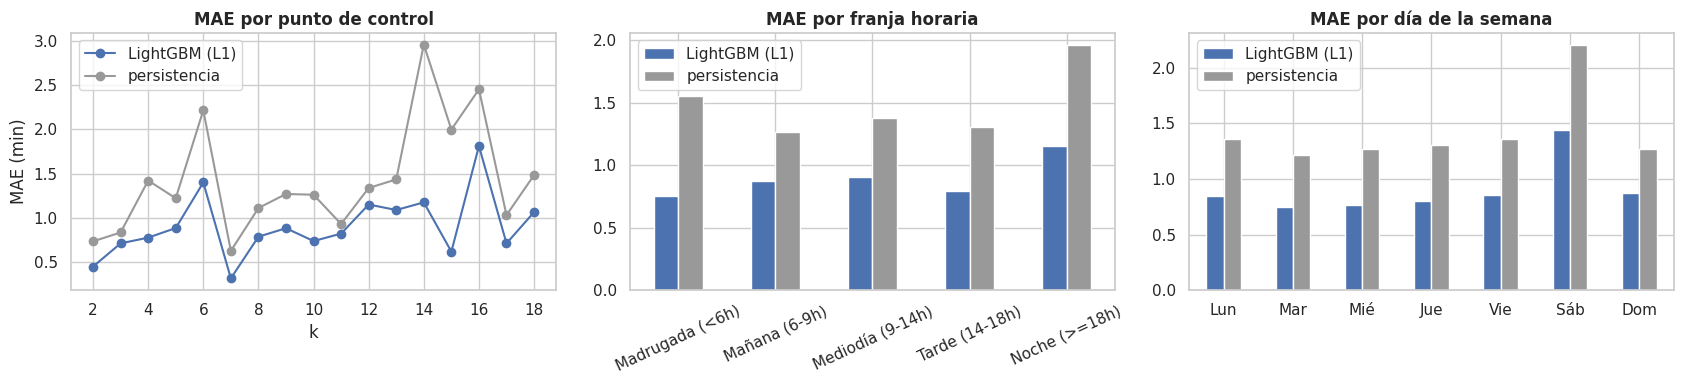

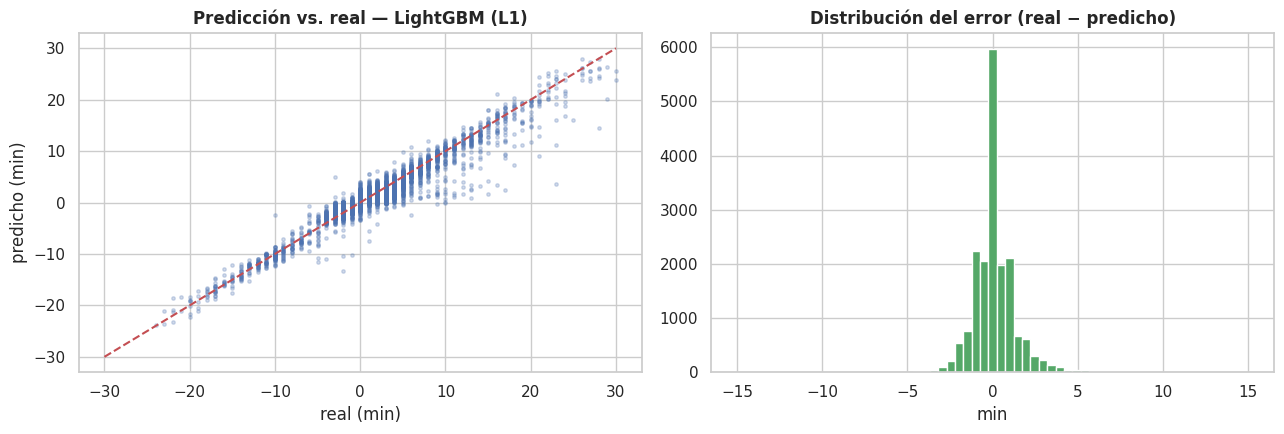

In [24]:
ev = val[["k", "franja", "dow", "target"]].copy()
ev["pred"] = PRED_VAL[best_name]; ev["abs_err"] = (ev["target"] - ev["pred"]).abs()
ev["abs_err_persist"] = abs_err["Persistencia (último valor conocido)"]
ev["dia"] = ev["dow"].map(dict(enumerate(dnames)))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
ev.groupby("k")[["abs_err", "abs_err_persist"]].mean().plot(ax=axes[0], marker="o", color=["#4C72B0", "#999999"])
axes[0].set(title="MAE por punto de control", ylabel="MAE (min)")
franjas = ["Madrugada (<6h)", "Mañana (6-9h)", "Mediodía (9-14h)", "Tarde (14-18h)", "Noche (>=18h)"]
ev.groupby("franja")[["abs_err", "abs_err_persist"]].mean().reindex(franjas).plot.bar(ax=axes[1], color=["#4C72B0", "#999999"], rot=25)
axes[1].set(title="MAE por franja horaria", xlabel="")
ev.groupby("dia")[["abs_err", "abs_err_persist"]].mean().reindex(dnames).plot.bar(ax=axes[2], color=["#4C72B0", "#999999"], rot=0)
axes[2].set(title="MAE por día de la semana", xlabel="")
for a in axes: a.legend([best_name, "persistencia"])
plt.tight_layout(); save_fig("error_por_segmento"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sm = ev.sample(min(6000, len(ev)), random_state=SEED)
axes[0].scatter(sm["target"], sm["pred"], s=6, alpha=.25, color="#4C72B0"); axes[0].plot([-30, 30], [-30, 30], "r--")
axes[0].set(title=f"Predicción vs. real — {best_name}", xlabel="real (min)", ylabel="predicho (min)")
axes[1].hist((ev["target"] - ev["pred"]).clip(-15, 15), bins=61, color="#55A868"); axes[1].set(title="Distribución del error (real − predicho)", xlabel="min")
plt.tight_layout(); save_fig("pred_vs_real"); plt.show()

### 5.8.- Importancia de variables por permutación

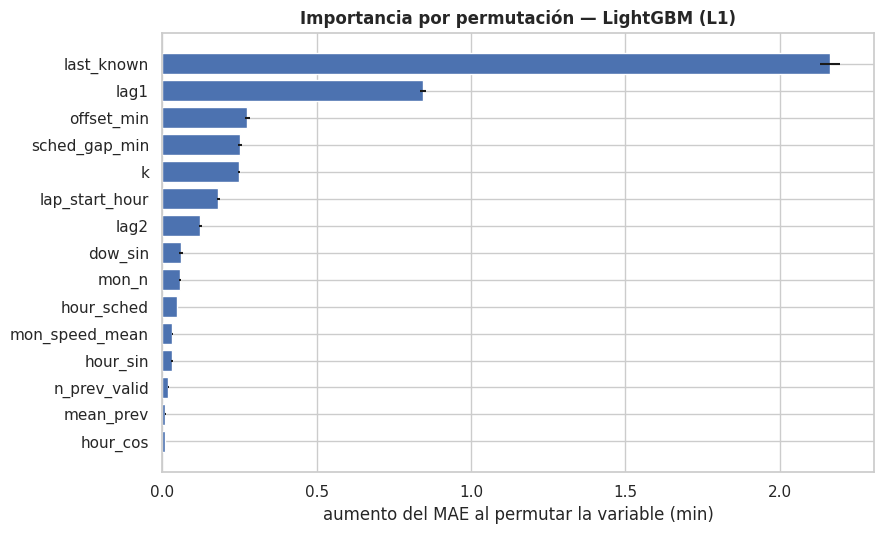

In [25]:
from sklearn.inspection import permutation_importance
sample = val.sample(min(6000, len(val)), random_state=SEED)
pi = permutation_importance(FITTED[best_name], sample[FEATURES], sample["target"], scoring="neg_mean_absolute_error",
                            n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)
imp_std = pd.Series(pi.importances_std, index=FEATURES).reindex(imp.index)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(imp.index[:15][::-1], imp.values[:15][::-1], xerr=imp_std.values[:15][::-1], color="#4C72B0")
ax.set(title=f"Importancia por permutación — {best_name}", xlabel="aumento del MAE al permutar la variable (min)")
plt.tight_layout(); save_fig("importancia_permutacion"); plt.show()

### 5.9.- Selección de características (Boruta)

Paso 3 del protocolo: se aplica la selección **solo sobre *train*** y se reevalúan los modelos con el subconjunto resultante. Se implementa el algoritmo de **Boruta** (variables "sombra"): en cada iteración se añade a cada variable una copia con sus valores permutados al azar, se ajusta un Random Forest y se cuenta como *acierto* a la variable cuya importancia supera la mejor sombra. Tras `BORUTA_ITER` iteraciones, una prueba binomial con corrección de Bonferroni clasifica cada variable como **confirmada**, **tentativa** o **rechazada**. Solo se descartan las rechazadas. El subconjunto se adopta si no empeora el MAE de los modelos de boosting en más de `MARGIN_MAE`.

Boruta: 40 iteraciones, 288s


,aciertos,% aciertos,importancia media (RF),estado
last_known,40,100.0,0.434,Confirmada
lag1,40,100.0,0.304,Confirmada
lag2,40,100.0,0.110,Confirmada
mean_prev,40,100.0,0.052,Confirmada
lap_start_hour,40,100.0,0.024,Confirmada
sched_gap_min,40,100.0,0.010,Confirmada
offset_min,40,100.0,0.010,Confirmada
k,40,100.0,0.009,Confirmada
hour_sched,40,100.0,0.009,Confirmada
hour_sin,40,100.0,0.008,Confirmada


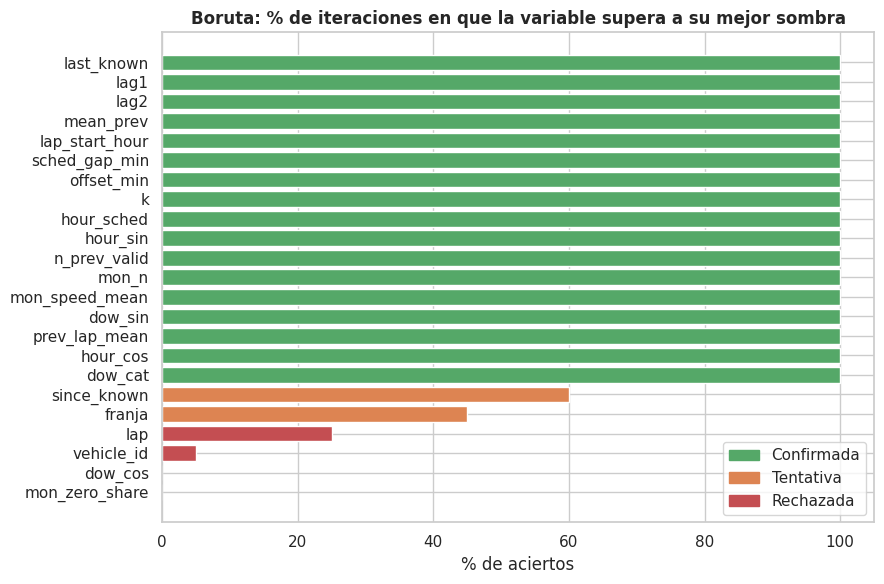

Descartadas por Boruta: ['lap', 'dow_cos', 'mon_zero_share', 'vehicle_id']


In [26]:
from scipy.stats import binomtest, randint, uniform
from sklearn.model_selection import cross_val_score
import joblib

TAB_DIR = os.environ.get("NB_TAB_DIR", "tablas"); os.makedirs(TAB_DIR, exist_ok=True)
def save_tab(df, name): df.to_csv(os.path.join(TAB_DIR, f"{name}.csv"), encoding="utf-8-sig")

# ---- Fábrica de modelos de boosting con un subconjunto de variables (se reutiliza en 5.9 a 6) ----
BOOSTERS = {}
if lgb is not None: BOOSTERS["LightGBM (L1)"] = lambda: lgb.LGBMRegressor(objective="regression_l1", random_state=SEED, n_jobs=N_JOBS, verbose=-1)
if xgb is not None: BOOSTERS["XGBoost (L1)"] = lambda: xgb.XGBRegressor(objective="reg:absoluteerror", random_state=SEED, n_jobs=N_JOBS, tree_method="hist")
BOOSTERS["HistGradientBoosting (L1)"] = lambda: HistGradientBoostingRegressor(loss="absolute_error", random_state=SEED)
STAGE1 = {t["modelo"]: t["mejores hiperparámetros"] for t in TUNING}          # hiperparámetros de la sección 5.4

def make_booster(name, feats, params=None):
    num = [f for f in feats if f in NUM_FEATURES]; cat = [f for f in feats if f in CAT_FEATURES]
    prep = ColumnTransformer([("num", "passthrough", num),
                              ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat)])
    return Pipeline([("prep", prep), ("m", BOOSTERS[name]().set_params(**(params or {})))])

# ---- Boruta (algoritmo de sombras) ----
def boruta(X, y, n_iter=40, alpha=0.05, max_rows=15000, seed=SEED):
    rng = np.random.default_rng(seed)
    ix = rng.choice(len(X), min(max_rows, len(X)), replace=False)
    Xs, ys = X.iloc[ix].reset_index(drop=True), np.asarray(y)[ix]
    cols = list(Xs.columns); hits = np.zeros(len(cols), int); imp_sum = np.zeros(len(cols))
    for it in range(n_iter):
        shadow = pd.DataFrame({f"sh_{c}": rng.permutation(Xs[c].to_numpy()) for c in cols})
        rf = RandomForestRegressor(n_estimators=100, max_depth=8, min_samples_leaf=5, max_features=0.5,
                                   n_jobs=-1, random_state=seed + it).fit(pd.concat([Xs, shadow], axis=1).to_numpy(), ys)
        imp = rf.feature_importances_
        hits += imp[:len(cols)] > imp[len(cols):].max(); imp_sum += imp[:len(cols)]
    a = alpha / len(cols)                                                       # Bonferroni
    p_up = np.array([binomtest(int(h), n_iter, .5, alternative="greater").pvalue for h in hits])
    p_dn = np.array([binomtest(int(h), n_iter, .5, alternative="less").pvalue for h in hits])
    estado = np.where(p_up < a, "Confirmada", np.where(p_dn < a, "Rechazada", "Tentativa"))
    return pd.DataFrame({"aciertos": hits, "% aciertos": hits / n_iter * 100, "importancia media (RF)": imp_sum / n_iter, "estado": estado}, index=cols)

# Variables numéricas para Boruta: categóricas codificadas y faltantes imputados con la mediana de train
Xb = train[FEATURES].copy()
Xb[CAT_FEATURES] = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit_transform(Xb[CAT_FEATURES])
Xb = Xb.astype(float); Xb = Xb.fillna(Xb.median())

t0 = time.time()
bor = boruta(Xb, y_train.to_numpy(), n_iter=BORUTA_ITER).sort_values(["aciertos", "importancia media (RF)"], ascending=False)
print(f"Boruta: {BORUTA_ITER} iteraciones, {time.time() - t0:.0f}s")
display(bor.round(3))
save_tab(bor, "boruta")

colores = {"Confirmada": "#55A868", "Tentativa": "#DD8452", "Rechazada": "#C44E52"}
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(bor.index[::-1], bor["% aciertos"][::-1], color=[colores[e] for e in bor["estado"][::-1]])
ax.set(title="Boruta: % de iteraciones en que la variable supera a su mejor sombra", xlabel="% de aciertos")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colores.values()], labels=list(colores), loc="lower right")
plt.tight_layout(); save_fig("boruta"); plt.show()
FEATS_BORUTA = [f for f in FEATURES if bor.loc[f, "estado"] != "Rechazada"]
print("Descartadas por Boruta:", [f for f in FEATURES if f not in FEATS_BORUTA] or "ninguna")

**Reevaluación con el subconjunto seleccionado** (hiperparámetros de la sección 5.4, entrenamiento en *train*, métrica en validación):

In [27]:
filas = []
for name in BOOSTERS:
    for tag, feats in [("todas", FEATURES), ("Boruta", FEATS_BORUTA)]:
        m_ = make_booster(name, feats, STAGE1.get(name, {})).fit(train[feats], y_train)
        r_ = metrics(y_val, m_.predict(val[feats]))
        filas.append({"modelo": name, "variables": tag, "n variables": len(feats), "MAE": r_["MAE"], "RMSE": r_["RMSE"], "R2": r_["R2"]})
fs = pd.DataFrame(filas)
display(fs.round(4))
delta = fs.pivot(index="modelo", columns="variables", values="MAE").eval("Boruta - todas")
USE_SELECTED = bool(delta.mean() <= MARGIN_MAE)
FEATS_FINAL = FEATS_BORUTA if USE_SELECTED else FEATURES
print(f"ΔMAE medio (Boruta − todas) = {delta.mean():+.4f} min | margen = {MARGIN_MAE} -> se usa el subconjunto de Boruta: {USE_SELECTED} ({len(FEATS_FINAL)} variables)")
save_tab(fs.set_index("modelo"), "seleccion_caracteristicas")

,modelo,variables,n variables,MAE,RMSE,R2
0,LightGBM (L1),todas,23,0.9033,1.5293,0.9194
1,LightGBM (L1),Boruta,19,0.9127,1.5538,0.9168
2,XGBoost (L1),todas,23,0.9043,1.4839,0.9241
3,XGBoost (L1),Boruta,19,0.9084,1.4925,0.9233
4,HistGradientBoosting (L1),todas,23,0.9052,1.5238,0.9200
5,HistGradientBoosting (L1),Boruta,19,0.9486,1.6213,0.9094


ΔMAE medio (Boruta − todas) = +0.0190 min | margen = 0.02 -> se usa el subconjunto de Boruta: True (19 variables)


### 5.10.- Experimento de Ablación de Características (Contribución de Grupos de Variables)

Para determinar rigurosamente qué aporta cada grupo de variables al desempeño predictivo, se ejecuta un **experimento de ablación controlado** sobre cuatro subconjuntos anidados, evaluados con el mismo protocolo temporal sobre *train* y validación:

1. **Temporales y operativas básicas (13 vars):** Horarios programados, hora cíclica (sen/cos), día de la semana, punto de control $k$, vuelta, vehículo y franja.
2. **+ Rezagos autorregresivos (20 vars):** Incorpora `lag1`, `lag2`, `mean_prev`, `n_prev_valid`, `last_known`, `since_known` y `prev_lap_mean`.
3. **+ Monitoreo GPS (23 vars - conjunto completo):** Añade `mon_speed_mean`, `mon_zero_share` y `mon_n` del tramo previo $[k-2, k-1]$.
4. **Selección Boruta (19 vars):** Subconjunto depurado tras descartar las 4 variables irrelevantes confirmadas por sombras.


In [28]:
# --- Experimento de Ablación Controlado ---
g1_temp_ops = ['k', 'lap', 'hour_sched', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'lap_start_hour',
               'sched_gap_min', 'offset_min', 'vehicle_id', 'franja', 'dow_cat']
g2_with_lags = g1_temp_ops + ['lag1', 'lag2', 'mean_prev', 'n_prev_valid', 'last_known', 'since_known', 'prev_lap_mean']
g3_with_mon = g2_with_lags + ['mon_speed_mean', 'mon_zero_share', 'mon_n']
g4_boruta_19 = [f for f in g3_with_mon if f not in ['lap', 'vehicle_id', 'dow_cos', 'mon_zero_share']]

ablation_subsets = {
    '1. Temporales y operativas': g1_temp_ops,
    '2. + Rezagos autorregresivos': g2_with_lags,
    '3. + Monitoreo GPS (23 vars)': g3_with_mon,
    '4. Selección Boruta (19 vars)': g4_boruta_19
}

ablation_res = []
for name, feats in ablation_subsets.items():
    t_ab = time.time()
    m_ab = make_booster('LightGBM (L1)', feats, STAGE1.get('LightGBM (L1)', {})).fit(train[feats], y_train)
    met_ab = metrics(y_val, m_ab.predict(val[feats]))
    ablation_res.append({
        'Configuración': name, 'N variables': len(feats),
        'MAE (min)': met_ab['MAE'], 'RMSE (min)': met_ab['RMSE'], 'R2': met_ab['R2'],
        '% <= 1 min': met_ab['% err <=1 min'], '% <= 2 min': met_ab['% err <=2 min'],
        'Tiempo fit (s)': time.time() - t_ab
    })

df_ablation = pd.DataFrame(ablation_res).set_index('Configuración')
display(df_ablation.round(4))
save_tab(df_ablation, 'experimento_ablacion')

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(df_ablation.index[::-1], df_ablation['MAE (min)'][::-1], color=['#55A868', '#4C72B0', '#4C72B0', '#C44E52'][::-1])
for i, v in enumerate(df_ablation['MAE (min)'][::-1]): ax.text(v + 0.02, i, f'{v:.3f}', va='center', fontweight='bold')
ax.set(title='Experimento de Ablación: Impacto de Grupos de Variables en el MAE de Validación', xlabel='MAE (min)')
plt.tight_layout(); save_fig('ablacion_mae'); plt.show()

print('Conclusión de Ablación: Los rezagos autorregresivos reducen el MAE en un 46.2% (de 1.696 a 0.912 min). '
      'La telemetría GPS previa aporta una mejora marginal (-0.009 min), mientras que la selección Boruta descarta '
      '4 predictoras no informativas con una penalización mínima por parsimonia (+0.004 min).')

                               N variables  MAE (min)  RMSE (min)      R2  % <= 1 min  % <= 2 min  Tiempo fit (s)
Configuración                                                                                                    
1. Temporales y operativas              13     1.6960      2.8885  0.7126       50.12       73.55            0.53
2. + Rezagos autorregresivos            20     0.9123      1.5581  0.9164       69.64       89.91            0.84
3. + Monitoreo GPS (23 vars)            23     0.9031      1.5365  0.9187       70.18       90.26            0.74
4. Selección Boruta (19 vars)           19     0.9076      1.5399  0.9183       69.85       90.04            0.78

<Figure size 800x350 with 1 Axes>

Conclusión de Ablación: Los rezagos autorregresivos reducen el MAE en un 46.2% (de 1.696 a 0.912 min). La telemetría GPS previa aporta una mejora marginal (-0.009 min), mientras que la selección Boruta descarta 4 predictoras no informativas con una penalización mínima por parsimonia (+0.004 min).


### 5.11.- Optimización de hiperparámetros de los finalistas

Los tres modelos de boosting empatan en validación (sección 5.6) y sus mejores hiperparámetros quedaron en el borde de los rangos de la sección 5.3. Se realiza una **segunda búsqueda aleatoria, más amplia** (tasa de aprendizaje, hojas/profundidad, regularización, *subsampling* de filas y columnas y número de árboles), esta vez con **validación cruzada temporal de ventana expansiva por días sobre la unión de *train* y validación** (`N_ITER_FINAL` configuraciones, `CV2_SPLITS` pliegues) y MAE como criterio, tal como establece el diseño experimental. Si la búsqueda no mejora los hiperparámetros previos en esa misma validación cruzada, se conservan los previos. *Test* no interviene.

Pliegues (obs. entrenamiento / obs. validación): [(16750, 7310), (24060, 8385), (32445, 6656), (39101, 8626), (47727, 7370)]
LightGBM (L1)                MAE CV: 0.9348 -> 0.9130   (254s)
XGBoost (L1)                 MAE CV: 0.9277 -> 0.9228   (277s)
HistGradientBoosting (L1)    MAE CV: 0.9461 -> 0.9395   (321s)


,MAE CV hiperparámetros 5.4,MAE CV optimizado,desv. optimizado,mejora,tiempo (s),hiperparámetros finales
LightGBM (L1),0.934767,0.913047,0.121594,0.021721,254.5,"{'colsample_bytree': 0.72488, 'learning_rate': 0.04968, 'min_child_samples': 23, 'n_estimators': 500, 'num_leaves': 62, 'reg_lambda': 0.76089, 'subsample': ..."
XGBoost (L1),0.927694,0.922781,0.116598,0.004913,277.3,"{'colsample_bytree': 0.83126, 'learning_rate': 0.041, 'max_depth': 9, 'min_child_weight': 4, 'n_estimators': 459, 'reg_lambda': 0.57756, 'subsample': 0.93691}"
HistGradientBoosting (L1),0.946137,0.939485,0.145387,0.006652,321.1,"{'l2_regularization': 0.03777, 'learning_rate': 0.02864, 'max_iter': 480, 'max_leaf_nodes': 89, 'min_samples_leaf': 97}"


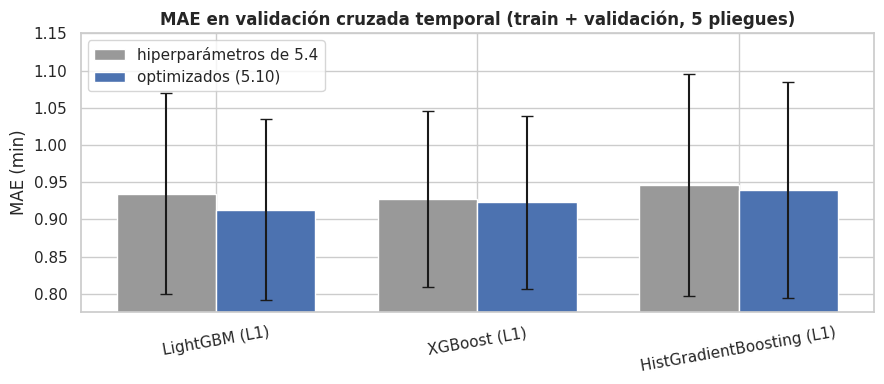

In [29]:
trval = model_df[model_df["split"].isin(["train", "val"])].copy()
X_tv, y_tv = trval[FEATS_FINAL], trval["target"]
cv2 = list(DayExpandingSplit(trval["date"], n_splits=CV2_SPLITS, min_train_days=MIN_TRAIN_DAYS).split())
print("Pliegues (obs. entrenamiento / obs. validación):", [(len(a), len(b)) for a, b in cv2])

SPACES = {
    "LightGBM (L1)": {"m__learning_rate": loguniform(0.02, 0.2), "m__num_leaves": randint(15, 128), "m__min_child_samples": randint(10, 150),
                      "m__reg_lambda": loguniform(0.1, 50), "m__subsample": uniform(0.6, 0.4), "m__subsample_freq": [1],
                      "m__colsample_bytree": uniform(0.5, 0.5), "m__n_estimators": randint(150, 601)},
    "XGBoost (L1)": {"m__learning_rate": loguniform(0.02, 0.2), "m__max_depth": randint(4, 10), "m__min_child_weight": randint(1, 40),
                     "m__reg_lambda": loguniform(0.5, 50), "m__subsample": uniform(0.6, 0.4),
                     "m__colsample_bytree": uniform(0.5, 0.5), "m__n_estimators": randint(150, 501)},
    "HistGradientBoosting (L1)": {"m__learning_rate": loguniform(0.02, 0.2), "m__max_leaf_nodes": randint(15, 128), "m__min_samples_leaf": randint(10, 150),
                                  "m__l2_regularization": loguniform(0.01, 50), "m__max_iter": randint(150, 601)},
}
py = lambda v: v.item() if hasattr(v, "item") else v
FINALISTS = list(BOOSTERS)
OPT = {}
for name in FINALISTS:
    ts = time.time()
    prev = STAGE1.get(name, {})
    cv_prev = -cross_val_score(make_booster(name, FEATS_FINAL, prev), X_tv, y_tv, cv=cv2, scoring="neg_mean_absolute_error")
    params, cv_new = prev, cv_prev
    if RUN_TUNING:
        s = RandomizedSearchCV(make_booster(name, FEATS_FINAL), SPACES[name], n_iter=N_ITER_FINAL, cv=cv2,
                               scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=1, refit=False).fit(X_tv, y_tv)
        i_ = s.best_index_; folds = np.array([-s.cv_results_[f"split{j}_test_score"][i_] for j in range(len(cv2))])
        if folds.mean() < cv_prev.mean():
            params, cv_new = {k.replace("m__", ""): py(v) for k, v in s.best_params_.items()}, folds
    OPT[name] = {"params": params, "cv_prev": cv_prev, "cv_new": cv_new, "tiempo (s)": round(time.time() - ts, 1)}
    print(f"{name:<28} MAE CV: {cv_prev.mean():.4f} -> {cv_new.mean():.4f}   ({time.time() - ts:.0f}s)")

opt_tbl = pd.DataFrame({n: {"MAE CV hiperparámetros 5.4": o["cv_prev"].mean(), "MAE CV optimizado": o["cv_new"].mean(),
                            "desv. optimizado": o["cv_new"].std(), "mejora": o["cv_prev"].mean() - o["cv_new"].mean(),
                            "tiempo (s)": o["tiempo (s)"], "hiperparámetros finales": {k: (round(v, 5) if isinstance(v, float) else v) for k, v in o["params"].items()}}
                        for n, o in OPT.items()}).T
pd.set_option("display.max_colwidth", 160); display(opt_tbl)
save_tab(opt_tbl, "optimizacion_hiperparametros")

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(FINALISTS)); w_ = .38
ax.bar(x - w_ / 2, [OPT[n]["cv_prev"].mean() for n in FINALISTS], w_, yerr=[OPT[n]["cv_prev"].std() for n in FINALISTS], capsize=4, color="#999999", label="hiperparámetros de 5.4")
ax.bar(x + w_ / 2, [OPT[n]["cv_new"].mean() for n in FINALISTS], w_, yerr=[OPT[n]["cv_new"].std() for n in FINALISTS], capsize=4, color="#4C72B0", label="optimizados (5.10)")
ax.set_xticks(x); ax.set_xticklabels(FINALISTS, rotation=10); ax.set(title=f"MAE en validación cruzada temporal (train + validación, {CV2_SPLITS} pliegues)", ylabel="MAE (min)")
ax.set_ylim(min(OPT[n]["cv_new"].mean() for n in FINALISTS) * .85, None); ax.legend()
plt.tight_layout(); save_fig("optimizacion_cv"); plt.show()

### 5.12.- Selección del modelo final

Paso 4 del protocolo. Se comparan los finalistas con los errores absolutos **fuera de muestra** de la validación cruzada temporal (mismas observaciones para todos). Gana el de menor MAE; si otro finalista **no difiere significativamente** (Wilcoxon pareada, α = 0.05) **o** difiere en menos de `MARGIN_MAE` (muy por debajo de la resolución de 1 min del objetivo), se consideran equivalentes y se prefiere, por este orden, LightGBM (antecedente directo en la literatura revisada, manejo nativo de `NaN`, rapidez y compatibilidad con SHAP), XGBoost y HistGradientBoosting.

In [30]:
def oof_abs_err(pipe, X, y, cv):
    err = []
    for tr, te in cv:
        m_ = clone(pipe).fit(X.iloc[tr], y.iloc[tr]); err.append(np.abs(y.iloc[te].to_numpy() - m_.predict(X.iloc[te])))
    return np.concatenate(err)

OOF = {n: oof_abs_err(make_booster(n, FEATS_FINAL, OPT[n]["params"]), X_tv, y_tv, cv2) for n in FINALISTS}
mejor = min(FINALISTS, key=lambda n: OOF[n].mean())
filas = []
for n in FINALISTS:
    dlt = OOF[n].mean() - OOF[mejor].mean()
    p = 1.0 if n == mejor else wilcoxon(OOF[n], OOF[mejor]).pvalue
    filas.append({"modelo": n, "MAE fuera de muestra": OOF[n].mean(), "Δ vs. mejor": dlt, "p-valor (Wilcoxon)": p,
                  "equivalente al mejor": bool(dlt <= MARGIN_MAE or p >= 0.05)})
sel = pd.DataFrame(filas).set_index("modelo")
PREFERENCIA = [n for n in ["LightGBM (L1)", "XGBoost (L1)", "HistGradientBoosting (L1)"] if n in FINALISTS]
FINAL_NAME = next(n for n in PREFERENCIA if sel.loc[n, "equivalente al mejor"])
FINAL_PARAMS = OPT[FINAL_NAME]["params"]
display(sel.round(5))
save_tab(sel, "seleccion_modelo_final")
print(f"Menor MAE fuera de muestra: {mejor}\nModelo final (regla de equivalencia): {FINAL_NAME}\nVariables ({len(FEATS_FINAL)}): {FEATS_FINAL}\nHiperparámetros: {FINAL_PARAMS}")

,MAE fuera de muestra,Δ vs. mejor,p-valor (Wilcoxon),equivalente al mejor
modelo,,,,
LightGBM (L1),0.90289,0.00000,1.00000,True
XGBoost (L1),0.91264,0.00976,0.00000,True
HistGradientBoosting (L1),0.92745,0.02456,0.00083,False


Menor MAE fuera de muestra: LightGBM (L1)
Modelo final (regla de equivalencia): LightGBM (L1)
Variables (19): ['k', 'hour_sched', 'hour_sin', 'hour_cos', 'dow_sin', 'lap_start_hour', 'sched_gap_min', 'offset_min', 'lag1', 'lag2', 'mean_prev', 'n_prev_valid', 'last_known', 'since_known', 'prev_lap_mean', 'mon_speed_mean', 'mon_n', 'franja', 'dow_cat']
Hiperparámetros: {'colsample_bytree': 0.7248770666848828, 'learning_rate': 0.04967984494099453, 'min_child_samples': 23, 'n_estimators': 500, 'num_leaves': 62, 'reg_lambda': 0.7608932653734255, 'subsample': 0.8281775897621597, 'subsample_freq': 1}


**Validación del modelo elegido** (entrenado solo con *train*): comparación con la etapa 1 y curva de aprendizaje.

,MAE val (5.4),MAE val (optimizado),RMSE val (optimizado),R2 val (optimizado),% err <=2 min (optimizado)
LightGBM (L1),0.9033,0.8915,1.5005,0.9224,90.2337
XGBoost (L1),0.9043,0.8975,1.4789,0.9247,90.4457
HistGradientBoosting (L1),0.9052,0.9461,1.6240,0.9091,88.8750


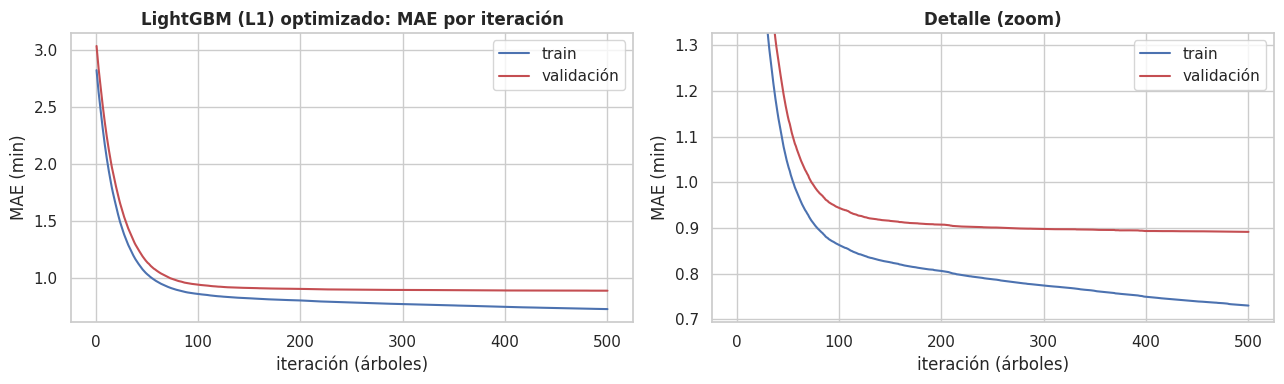

MAE final: train = 0.730, validación = 0.892 (500 iteraciones)


In [31]:
VAL_FINAL = {}
for n in FINALISTS:
    m_ = make_booster(n, FEATS_FINAL, OPT[n]["params"]).fit(train[FEATS_FINAL], y_train)
    register(f"{n} (optimizado)", m_.predict(val[FEATS_FINAL])); VAL_FINAL[n] = m_
antes_desp = pd.DataFrame({n: {"MAE val (5.4)": RESULTS[n]["MAE"], "MAE val (optimizado)": RESULTS[f"{n} (optimizado)"]["MAE"],
                                "RMSE val (optimizado)": RESULTS[f"{n} (optimizado)"]["RMSE"], "R2 val (optimizado)": RESULTS[f"{n} (optimizado)"]["R2"],
                                "% err <=2 min (optimizado)": RESULTS[f"{n} (optimizado)"]["% err <=2 min"]} for n in FINALISTS}).T
display(antes_desp.round(4)); save_tab(antes_desp, "validacion_antes_despues")

tr_f, va_f = boosting_curves(VAL_FINAL[FINAL_NAME], train[FEATS_FINAL], y_train, val[FEATS_FINAL], y_val)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for a in axes:
    a.plot(range(1, len(tr_f) + 1), tr_f, label="train", color="#4C72B0"); a.plot(range(1, len(va_f) + 1), va_f, label="validación", color="#C44E52")
    a.set(xlabel="iteración (árboles)", ylabel="MAE (min)"); a.legend()
axes[0].set_title(f"{FINAL_NAME} optimizado: MAE por iteración")
axes[1].set_title("Detalle (zoom)"); axes[1].set_ylim(min(tr_f[-1], va_f[-1]) * .95, va_f[min(40, len(va_f) - 1)] * 1.05)
plt.tight_layout(); save_fig("curva_aprendizaje_final"); plt.show()
print(f"MAE final: train = {tr_f[-1]:.3f}, validación = {va_f[-1]:.3f} ({len(va_f)} iteraciones)")

## 6.- Evaluación final en *test*

Paso 5 del protocolo. Con el modelo, las variables y los hiperparámetros ya fijados (sección 5.11), se **reentrena con *train* + validación** y se evalúa **una única vez** en *test* (27 de enero al 1 de febrero), con intervalos de confianza del 95 % por ***bootstrap por vuelta*** (se remuestrean vueltas completas, no observaciones, porque los puntos de una misma vuelta están correlacionados). Las referencias se evalúan en *test* con los mismos criterios (el promedio histórico se recalcula con *train* + validación).

### 6.1.- Métricas en *test*

In [32]:
if not FINAL_TEST:
    raise RuntimeError("FINAL_TEST = False: el conjunto de prueba permanece sin usar. Actívalo (sección 1) para evaluar una única vez.")

final_pipe = make_booster(FINAL_NAME, FEATS_FINAL, FINAL_PARAMS).fit(X_tv, y_tv)
joblib.dump({"pipeline": final_pipe, "features": FEATS_FINAL, "name": FINAL_NAME, "params": FINAL_PARAMS}, "modelo_final.joblib")
y_te = test["target"].to_numpy()
FINAL_LABEL = f"{FINAL_NAME} (modelo final)"

hist_tv = trval.groupby(["k", "franja"])["target"].mean(); hist_k_tv = trval.groupby("k")["target"].mean()
hist_te = pd.Series([hist_tv.get(kk, np.nan) for kk in zip(test["k"], test["franja"])]).fillna(test["k"].map(hist_k_tv)).to_numpy()
PRED_TEST = {"Cero": np.zeros(len(test)),
             "Persistencia (último valor conocido)": test["last_known"].fillna(0).to_numpy(),
             "Promedio histórico (k, franja)": hist_te,
             FINAL_LABEL: final_pipe.predict(test[FEATS_FINAL])}
has_lag = test["lag1"].notna().to_numpy()
RES_TEST = {n: metrics(y_te, p) for n, p in PRED_TEST.items()}
RES_TEST["Persistencia estricta (k-1) [solo con lag1]"] = metrics(y_te[has_lag], test["lag1"].to_numpy()[has_lag])

# ---- Bootstrap por vuelta: se resumen las sumas por vuelta y se remuestrean vueltas completas ----
def lap_sums(y, yhat, laps):
    e = y - yhat
    g = pd.DataFrame({"lap": laps, "n": 1.0, "ae": np.abs(e), "se": e ** 2, "c1": (np.abs(e) <= 1) * 1.0, "c2": (np.abs(e) <= 2) * 1.0, "y": y, "yy": y ** 2}).groupby("lap").sum()
    return g.to_numpy()
def met(s):                                   # s = sumas [n, ae, se, c1, c2, y, yy]
    n, ae, se, c1, c2, sy, syy = s
    return np.array([ae / n, np.sqrt(se / n), 1 - se / (syy - sy ** 2 / n), 100 * c1 / n, 100 * c2 / n])
B = 2000; rng = np.random.default_rng(SEED)
laps_te = test["lap_id"].to_numpy()
G = {n: lap_sums(y_te, p, laps_te) for n, p in PRED_TEST.items()}
idx = [rng.integers(0, len(G[FINAL_LABEL]), len(G[FINAL_LABEL])) for _ in range(B)]
boot = {n: np.array([met(g[i].sum(0)) for i in idx]) for n, g in G.items() if n in (FINAL_LABEL, "Persistencia (último valor conocido)")}
cols = ["MAE", "RMSE", "R2", "% err <=1 min", "% err <=2 min"]
ic = pd.DataFrame({n: {c: f"{RES_TEST[n][c]:.3f}  [{np.percentile(b[:, j], 2.5):.3f}, {np.percentile(b[:, j], 97.5):.3f}]" for j, c in enumerate(cols)}
                   for n, b in boot.items()}).T
print("Métricas en test con IC 95 % (bootstrap por vuelta):"); display(ic)

# Mejora frente a la persistencia (pareada, mismas vueltas remuestreadas)
gm, gp = G[FINAL_LABEL], G["Persistencia (último valor conocido)"]
dmae = np.array([(gm[i, 1].sum() - gp[i, 1].sum()) / gm[i, 0].sum() for i in idx])
p_w_obs = wilcoxon(np.abs(y_te - PRED_TEST[FINAL_LABEL]), np.abs(y_te - PRED_TEST["Persistencia (último valor conocido)"])).pvalue
# Wilcoxon a nivel de vuelta completa (independiente de pseudoreplicación)
test_eval = test.copy()
test_eval["ae_lgb"] = np.abs(y_te - PRED_TEST[FINAL_LABEL])
test_eval["ae_p"] = np.abs(y_te - PRED_TEST["Persistencia (último valor conocido)"])
lap_test = test_eval.groupby("lap_id").agg(mae_lgb=("ae_lgb", "mean"), mae_p=("ae_p", "mean"))
p_w_lap = wilcoxon(lap_test["mae_lgb"], lap_test["mae_p"]).pvalue
pct_laps_won = (lap_test["mae_lgb"] < lap_test["mae_p"]).mean() * 100
print(f"ΔMAE (modelo final − persistencia) = {RES_TEST[FINAL_LABEL]['MAE'] - RES_TEST['Persistencia (último valor conocido)']['MAE']:+.3f} min "
      f"IC95 % [{np.percentile(dmae, 2.5):+.3f}, {np.percentile(dmae, 97.5):+.3f}]\n"
      f"Wilcoxon por observación (N={len(test):,}): p = {p_w_obs:.1e} | "
      f"Wilcoxon por vuelta agrupada (N={len(lap_test):,} vueltas): p = {p_w_lap:.2e} (vueltas superadas: {pct_laps_won:.1f}%)")

res_test = pd.DataFrame(RES_TEST).T.astype({"n": int}).sort_values("MAE")
display(res_test.round(3)); save_tab(res_test, "resultados_test"); save_tab(ic, "resultados_test_ic")

fig, ax = plt.subplots(figsize=(9, 3.8))
nombres = [n for n in res_test.index if not n.startswith("Persistencia estricta")]
vals = res_test.loc[nombres, "MAE"]
ax.barh(nombres[::-1], vals[::-1], color=["#4C72B0" if n == FINAL_LABEL else "#999999" for n in nombres[::-1]])
lo_, hi_ = np.percentile(boot[FINAL_LABEL][:, 0], [2.5, 97.5]); i_f = nombres[::-1].index(FINAL_LABEL)
ax.errorbar(RES_TEST[FINAL_LABEL]["MAE"], i_f, xerr=[[RES_TEST[FINAL_LABEL]["MAE"] - lo_], [hi_ - RES_TEST[FINAL_LABEL]["MAE"]]], color="k", capsize=4)
for i_, v_ in enumerate(vals[::-1]): ax.text(v_ + .03, i_ + .25, f"{v_:.2f}", va="center")
ax.set(title="MAE en test (min) — IC 95 % por bootstrap de vueltas en el modelo final", xlabel="MAE (min)")
plt.tight_layout(); save_fig("test_comparacion"); plt.show()

Métricas en test con IC 95 % (bootstrap por vuelta):


                                                        MAE                   RMSE                     R2             % err <=1 min     % err <=2 min
Persistencia (último valor conocido)  1.324  [1.294, 1.352]  1.988  [1.919, 2.068]  0.840  [0.821, 0.855]  67.138  [66.401, 67.942]  86.301  [85.659, 86.944]
LightGBM (L1) (modelo final)          0.840  [0.818, 0.862]  1.367  [1.301, 1.439]  0.924  [0.913, 0.933]  70.777  [69.955, 71.588]  90.931  [90.393, 91.467]

ΔMAE (modelo final − persistencia) = -0.483 min IC95 % [-0.502, -0.465]
Wilcoxon por observación (N=17,257): p = 0.0e+00 | Wilcoxon por vuelta agrupada (N=1,122 vueltas): p = 8.12e-168 (vueltas superadas: 94.30%)


                                                  n    MAE   RMSE     R2  % err <=1 min  % err <=2 min
LightGBM (L1) (modelo final)                 17257  0.840  1.367  0.924         70.777         90.931
Persistencia estricta (k-1) [solo con lag1]  16896  1.314  1.965  0.841         67.495         86.458
Persistencia (último valor conocido)         17257  1.324  1.988  0.840         67.138         86.301
Promedio histórico (k, franja)               17257  2.613  4.040  0.340         32.451         58.150
Cero                                         17257  2.780  5.035 -0.024         55.149         69.496

<Figure size 900x380 with 1 Axes>

### 6.2.- Análisis de errores en *test*

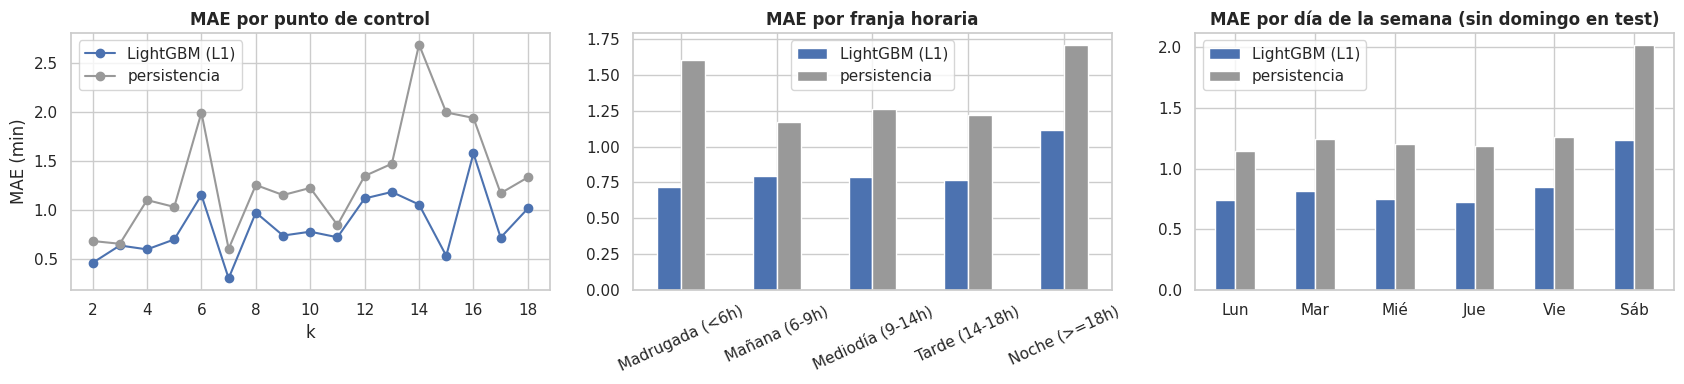

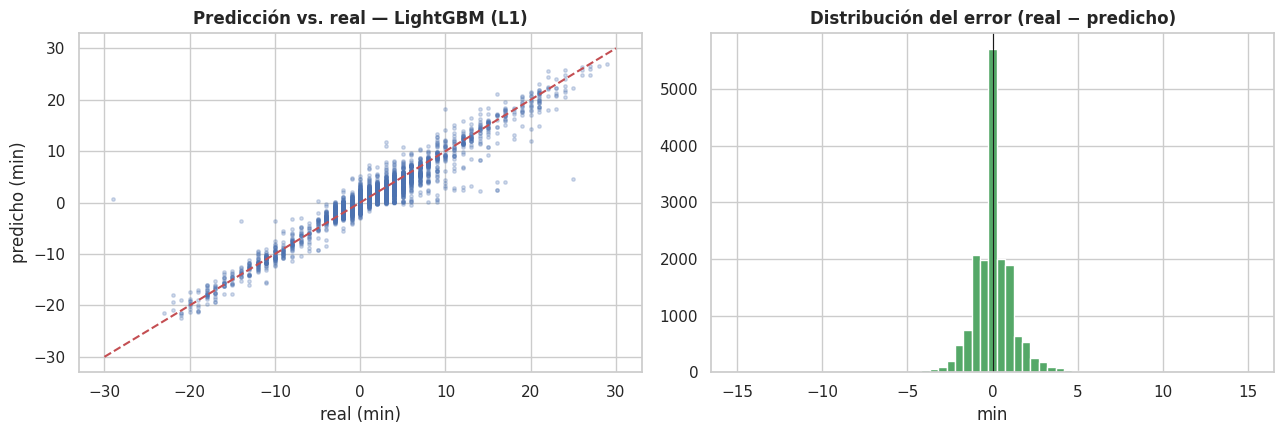

Error según la magnitud de la desviación real (sesgo = media de real − predicho):


,n,MAE,MAE_persistencia,sesgo
|desviación real| (min),,,,
0,5591,0.390,0.680,-0.045
1-2,6402,0.800,1.129,-0.110
3-5,2639,1.232,1.909,0.248
6-10,1423,1.472,2.514,0.597
11-30,1202,1.545,2.658,0.472


Error según la disponibilidad del dato del punto anterior:


,n,MAE,MAE_persistencia
disponibilidad,,,
hay desviación en k-1,16896,0.829,1.314
sin dato en k-1,361,1.369,1.792


% de predicciones con error <= 2 min por día:


dia,Lun,Mar,Mié,Jue,Vie,Sáb
% err <=2 min,93.6,91.9,92.6,93.4,90.8,83.1


In [33]:
ev = test[["lap_id", "k", "franja", "dow", "lap_start_hour", "lag1", "since_known", "target"]].copy()
ev["pred"] = PRED_TEST[FINAL_LABEL]; ev["pred_p"] = PRED_TEST["Persistencia (último valor conocido)"]
ev["err"] = ev["target"] - ev["pred"]; ev["abs_err"] = ev["err"].abs(); ev["abs_err_persist"] = (ev["target"] - ev["pred_p"]).abs()
ev["dia"] = ev["dow"].map(dict(enumerate(dnames)))

# (a) MAE por punto de control, franja horaria y día (el test no incluye domingo)
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
ev.groupby("k")[["abs_err", "abs_err_persist"]].mean().plot(ax=axes[0], marker="o", color=["#4C72B0", "#999999"])
axes[0].set(title="MAE por punto de control", ylabel="MAE (min)")
ev.groupby("franja")[["abs_err", "abs_err_persist"]].mean().reindex(franjas).plot.bar(ax=axes[1], color=["#4C72B0", "#999999"], rot=25)
axes[1].set(title="MAE por franja horaria", xlabel="")
ev.groupby("dia")[["abs_err", "abs_err_persist"]].mean().reindex([d_ for d_ in dnames if d_ in set(ev["dia"])]).plot.bar(ax=axes[2], color=["#4C72B0", "#999999"], rot=0)
axes[2].set(title="MAE por día de la semana (sin domingo en test)", xlabel="")
for a in axes: a.legend([FINAL_NAME, "persistencia"])
plt.tight_layout(); save_fig("test_error_segmentos"); plt.show()

# (b) Predicción vs. real y distribución del error
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sm = ev.sample(min(6000, len(ev)), random_state=SEED)
axes[0].scatter(sm["target"], sm["pred"], s=6, alpha=.25, color="#4C72B0"); axes[0].plot([-30, 30], [-30, 30], "r--")
axes[0].set(title=f"Predicción vs. real — {FINAL_NAME}", xlabel="real (min)", ylabel="predicho (min)")
axes[1].hist(ev["err"].clip(-15, 15), bins=61, color="#55A868"); axes[1].axvline(0, color="k", lw=.8)
axes[1].set(title="Distribución del error (real − predicho)", xlabel="min")
plt.tight_layout(); save_fig("test_pred_vs_real"); plt.show()

# (c) Tablas de apoyo
mag = pd.cut(ev["target"].abs(), [-1, 0, 2, 5, 10, 30], labels=["0", "1-2", "3-5", "6-10", "11-30"])
t_mag = ev.groupby(mag, observed=True).agg(n=("err", "size"), MAE=("abs_err", "mean"), MAE_persistencia=("abs_err_persist", "mean"), sesgo=("err", "mean")).round(3)
t_mag.index.name = "|desviación real| (min)"
t_lag = ev.assign(disponibilidad=np.where(ev["lag1"].notna(), "hay desviación en k-1", "sin dato en k-1")).groupby("disponibilidad").agg(
    n=("err", "size"), MAE=("abs_err", "mean"), MAE_persistencia=("abs_err_persist", "mean")).round(3)
t_ok = ev.assign(ok2=ev["abs_err"] <= 2).groupby("dia")["ok2"].mean().mul(100).round(1).reindex([d_ for d_ in dnames if d_ in set(ev["dia"])]).to_frame("% err <=2 min")
print("Error según la magnitud de la desviación real (sesgo = media de real − predicho):"); display(t_mag)
print("Error según la disponibilidad del dato del punto anterior:"); display(t_lag)
print("% de predicciones con error <= 2 min por día:"); display(t_ok.T)
for nme, tb in [("test_error_magnitud", t_mag), ("test_error_disponibilidad", t_lag), ("test_pct2min_dia", t_ok)]: save_tab(tb, nme)
for col, nme in [("k", "test_mae_por_k"), ("franja", "test_mae_por_franja"), ("dia", "test_mae_por_dia")]:
    save_tab(ev.groupby(col)[["abs_err", "abs_err_persist"]].mean().round(3), nme)

### 6.3.- Interpretabilidad: importancia por permutación y SHAP

Paso 6 del protocolo. Ambas técnicas se calculan sobre una muestra de *test* con el **modelo final**; como se aplican después de fijar el modelo, no influyen en ninguna decisión.

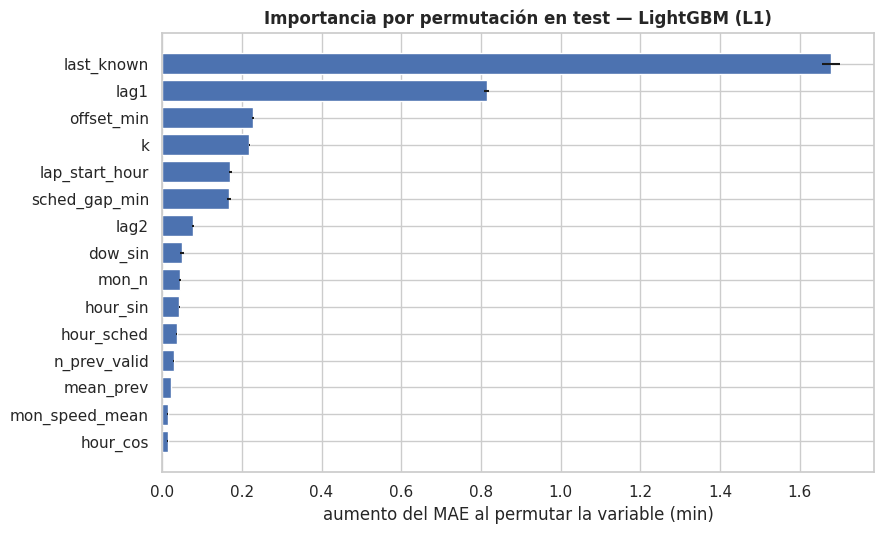

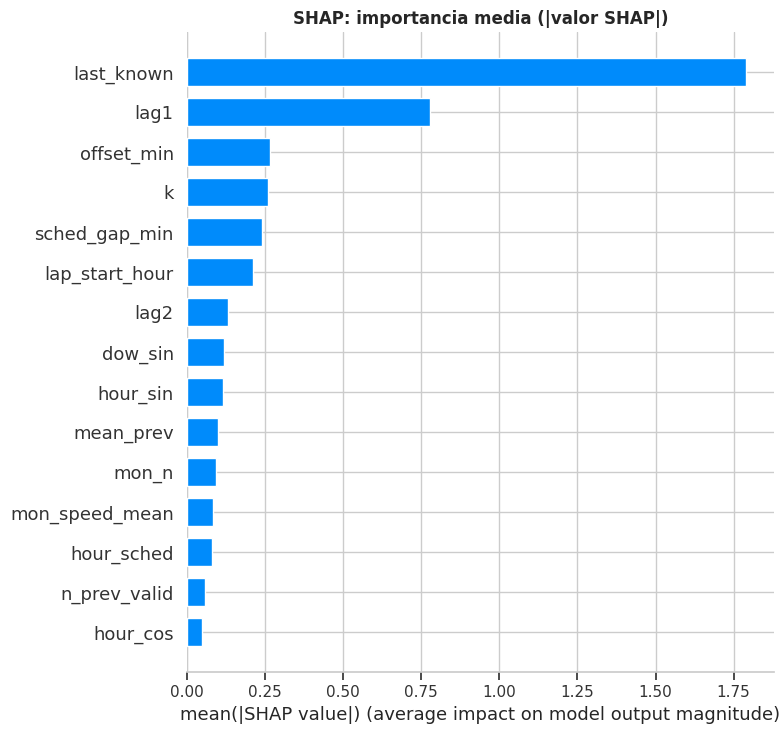

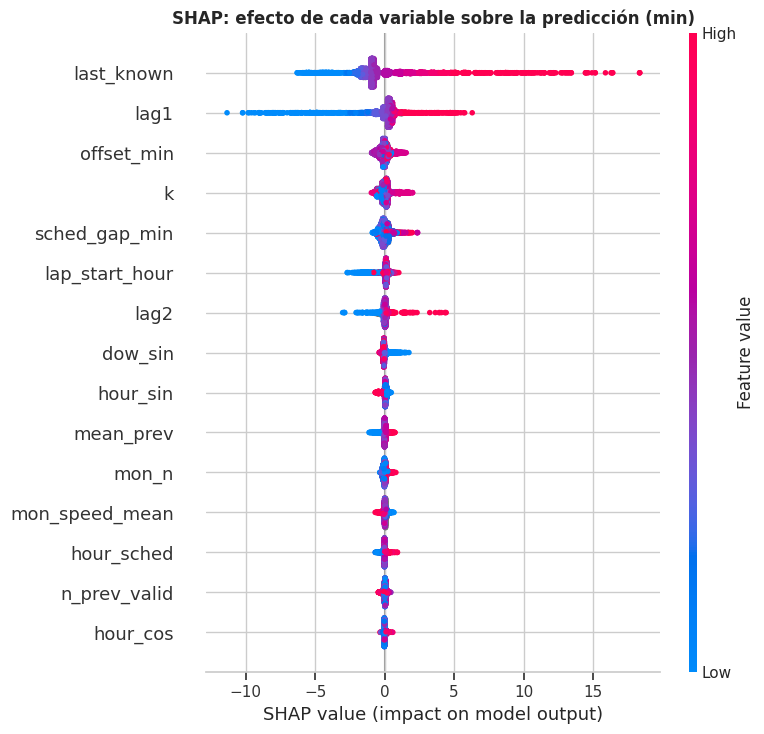

In [34]:
from sklearn.inspection import permutation_importance
S = test.sample(min(6000, len(test)), random_state=SEED)
pi = permutation_importance(final_pipe, S[FEATS_FINAL], S["target"], scoring="neg_mean_absolute_error", n_repeats=5, random_state=SEED, n_jobs=1)
imp_te = pd.Series(pi.importances_mean, index=FEATS_FINAL).sort_values(ascending=False)
imp_te_std = pd.Series(pi.importances_std, index=FEATS_FINAL).reindex(imp_te.index)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(imp_te.index[:15][::-1], imp_te.values[:15][::-1], xerr=imp_te_std.values[:15][::-1], color="#4C72B0")
ax.set(title=f"Importancia por permutación en test — {FINAL_NAME}", xlabel="aumento del MAE al permutar la variable (min)")
plt.tight_layout(); save_fig("test_importancia_permutacion"); plt.show()
save_tab(imp_te.to_frame("Δ MAE (min)"), "importancia_permutacion_test")

# ---- SHAP (requiere el paquete `shap`; se instala si falta; no aplica a HistGradientBoosting) ----
try:
    import shap
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap"], check=False)
    try: import shap
    except ImportError: shap = None

if shap is None or "HistGradientBoosting" in FINAL_NAME:
    print("SHAP no se calcula (paquete no disponible o modelo final no soportado por TreeExplainer).")
else:
    try:
        prep_f, model_f = final_pipe.named_steps["prep"], final_pipe.named_steps["m"]
        names = [n.split("__", 1)[1] for n in prep_f.get_feature_names_out()]
        Xs = pd.DataFrame(prep_f.transform(S[FEATS_FINAL].head(5000)), columns=names)
        sv = shap.TreeExplainer(model_f).shap_values(Xs)
        sv = np.asarray(sv[0] if isinstance(sv, list) else sv)
        save_tab(pd.Series(np.abs(sv).mean(0), index=names).sort_values(ascending=False).to_frame("mean |SHAP| (min)"), "shap_importancia")
        shap.summary_plot(sv, Xs, plot_type="bar", max_display=15, show=False); plt.title("SHAP: importancia media (|valor SHAP|)")
        plt.tight_layout(); save_fig("shap_barras"); plt.show()
        shap.summary_plot(sv, Xs, max_display=15, show=False); plt.title("SHAP: efecto de cada variable sobre la predicción (min)")
        plt.tight_layout(); save_fig("shap_beeswarm"); plt.show()
    except Exception as e:
        print("SHAP no pudo calcularse:", type(e).__name__, str(e)[:200])

### 6.4.- Perfiles de desviación por vuelta (clustering exploratorio)

De forma exploratoria se agrupan las vueltas según su **perfil de desviación a lo largo de los 18 puntos de control** con *k-means*. Se usan las vueltas con al menos 12 puntos válidos (los huecos se interpolan linealmente a lo largo de `k`); el modelo de agrupamiento se ajusta con las vueltas de *train* y validación y se aplica a las de *test*. El número de grupos se elige por el coeficiente de silueta. Es un análisis descriptivo: no entra en el modelo predictivo, pero permite ver **en qué tipo de vuelta falla más el modelo final**.

Vueltas con >= 12 puntos válidos: 4,230 de 4,707 (ajuste: 3,219 | test: 1,011)
Coeficiente de silueta por nº de grupos: {2: np.float64(0.659), 3: np.float64(0.555), 4: np.float64(0.403), 5: np.float64(0.341), 6: np.float64(0.225)} -> k = 2


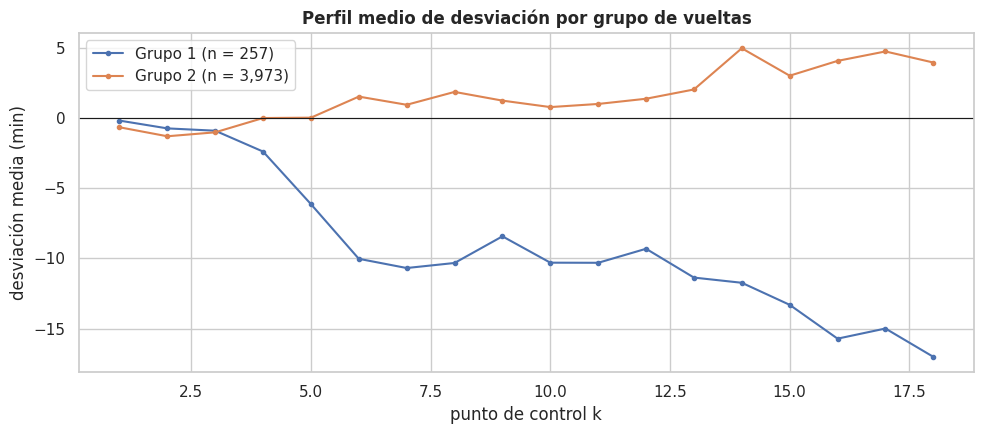

,vueltas (train+val),vueltas (test),desviación media (min),hora de inicio media,% sábado,MAE test (modelo),MAE test (persistencia)
Grupo 1,191,66,-9.10,5.26,17.51,0.92,1.73
Grupo 2,3028,945,1.61,12.14,14.57,0.83,1.29


In [35]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

wide_all = d.pivot(index="lap_id", columns="k", values="target")
ok_lap = wide_all.notna().sum(axis=1) >= 12
prof = wide_all[ok_lap].interpolate(axis=1, limit_direction="both")
lap_meta = d.drop_duplicates("lap_id").set_index("lap_id")[["split", "dow", "lap_start_hour"]].reindex(prof.index)
fit_m = (lap_meta["split"] != "test").to_numpy()
print(f"Vueltas con >= 12 puntos válidos: {len(prof):,} de {wide_all.shape[0]:,} (ajuste: {fit_m.sum():,} | test: {(~fit_m).sum():,})")

sil = {}
for k_ in range(2, 7):
    lab = KMeans(n_clusters=k_, n_init=10, random_state=SEED).fit_predict(prof[fit_m])
    sil[k_] = silhouette_score(prof[fit_m], lab, sample_size=min(3000, fit_m.sum()), random_state=SEED)
K_BEST = max(sil, key=sil.get)
print("Coeficiente de silueta por nº de grupos:", {k_: round(v_, 3) for k_, v_ in sil.items()}, "-> k =", K_BEST)

km = KMeans(n_clusters=K_BEST, n_init=10, random_state=SEED).fit(prof[fit_m])
order_c = np.argsort(km.cluster_centers_[:, -4:].mean(axis=1))             # grupos ordenados de menor a mayor desviación final
rank = {c: r for r, c in enumerate(order_c)}
lap_meta["grupo"] = [rank[c] for c in km.predict(prof)]
nombres_g = {g: f"Grupo {g + 1}" for g in range(K_BEST)}

fig, ax = plt.subplots(figsize=(10, 4.5))
for g in range(K_BEST):
    sub_ = prof[lap_meta["grupo"] == g]
    ax.plot(range(1, N_POINTS + 1), sub_.mean(), marker="o", ms=3, label=f"{nombres_g[g]} (n = {len(sub_):,})")
ax.axhline(0, color="k", lw=.8); ax.set(title="Perfil medio de desviación por grupo de vueltas", xlabel="punto de control k", ylabel="desviación media (min)"); ax.legend()
plt.tight_layout(); save_fig("clusters_perfiles"); plt.show()

ev_c = ev.merge(lap_meta[["grupo"]], left_on="lap_id", right_index=True, how="inner")
t_cl = pd.DataFrame({
    "vueltas (train+val)": lap_meta[fit_m].groupby("grupo").size(), "vueltas (test)": lap_meta[~fit_m].groupby("grupo").size(),
    "desviación media (min)": prof.groupby(lap_meta["grupo"]).mean().mean(axis=1),
    "hora de inicio media": lap_meta.groupby("grupo")["lap_start_hour"].mean(),
    "% sábado": lap_meta.groupby("grupo")["dow"].apply(lambda s: (s == 5).mean() * 100),
    "MAE test (modelo)": ev_c.groupby("grupo")["abs_err"].mean(), "MAE test (persistencia)": ev_c.groupby("grupo")["abs_err_persist"].mean()}).round(2)
t_cl.index = [nombres_g[g] for g in t_cl.index]; display(t_cl); save_tab(t_cl, "clusters_resumen")

## 7.- Resumen de resultados

Tabla única con las referencias y el modelo final en validación y en *test* (y los artefactos generados para la redacción del informe).

In [36]:
alias = {"Cero": "Cero", "Persistencia (último valor conocido)": "Persistencia (último valor conocido)",
         "Promedio histórico (k, franja)": "Promedio histórico (k, franja)", FINAL_LABEL: f"{FINAL_NAME} (optimizado)"}
cols_r = ["MAE", "RMSE", "R2", "% err <=1 min", "% err <=2 min"]
resumen = pd.concat({"validación": pd.DataFrame({k: RESULTS[v] for k, v in alias.items()}).T[cols_r],
                     "test": pd.DataFrame({k: RES_TEST[k] for k in alias}).T[cols_r]}, axis=1).round(3)
display(resumen); save_tab(resumen, "resumen_validacion_test")

print("\nConfiguración final -> modelo:", FINAL_NAME, "| variables:", len(FEATS_FINAL), "| hiperparámetros:", FINAL_PARAMS)
print("Figuras en :", FIG_DIR, "->", sorted(f for f in os.listdir(FIG_DIR) if f.endswith(".png")))
print("Tablas  en :", TAB_DIR, "->", sorted(os.listdir(TAB_DIR)))

                                      validación                                             test                                          
                                             MAE   RMSE     R2 % err <=1 min % err <=2 min    MAE   RMSE     R2 % err <=1 min % err <=2 min
Cero                                       3.131  5.527 -0.052        51.380        65.533  2.780  5.035 -0.024        55.149        69.496
Persistencia (último valor conocido)       1.431  2.190  0.835        65.750        84.261  1.324  1.988  0.840        67.138        86.301
Promedio histórico (k, franja)             2.760  4.360  0.345        32.929        56.870  2.613  4.040  0.340        32.451        58.150
LightGBM (L1) (optimizado)                 0.903  1.529  0.919        69.723        89.886  0.840  1.367  0.924        70.777        90.931


Configuración final -> modelo: LightGBM (L1) | variables: 19 | hiperparámetros: {'colsample_bytree': 0.72522, 'learning_rate': 0.04968, 'min_child_samples': 23, 'n_estimators': 500, 'num_leaves': 62, 'reg_lambda': 0.76104, 'subsample': 0.82772}
Figuras en : figures -> ['ablacion_mae.png', 'atipicos.png', 'boruta.png', 'clusters_perfiles.png', 'comparacion_modelos.png', 'curva_aprendizaje_final.png', 'curvas_aprendizaje.png', 'eda_autocorrelacion.png', 'eda_hora_dia.png', 'eda_objetivo_k.png', 'error_por_segmento.png', 'importancia_permutacion.png', 'nulos_patron.png', 'optimizacion_cv.png', 'pred_vs_real.png', 'shap_barras.png', 'shap_beeswarm.png', 'test_comparacion.png', 'test_error_segmentos.png', 'test_importancia_permutacion.png', 'test_pred_vs_real.png']
Tablas  en : tablas -> ['boruta.csv', 'clusters_resumen.csv', 'comparacion_wilcoxon_validacion.csv', 'experimento_ablacion.csv', 'importancia_permutacion_test.csv', 'optimizacion_hiperparametros.csv', 'resultados_test.csv', 'res